In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split # Import train_test_split to split data into train, validation, and test sets.
from sklearn.preprocessing import LabelEncoder # Encode target labels with value between 0 and n_classes-1.
from sklearn.preprocessing import OneHotEncoder  # Import OneHotEncoder to convert categorical columns into numeric columns.
from sklearn.compose import ColumnTransformer # Import ColumnTransformer to apply different preprocessing steps to different column types.
from sklearn.pipeline import Pipeline # Import Pipeline to combine preprocessing steps in a clean workflow.
from sklearn.impute import SimpleImputer # Import SimpleImputer to handle missing values after train-test split.
from sklearn.metrics import classification_report # Build a text report showing the main classification metrics.
from sklearn.metrics import confusion_matrix # to evaluate the accuracy of a classification
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score # # Import roc_auc_score to calculate ROC-AUC score.
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier # Import ExtraTreesClassifier to build an extremely randomized trees ensemble model.
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
!pip -q install imbalanced-learn
from imblearn.over_sampling import SMOTE # to perform over-sampling using SMOTE.
from imblearn.over_sampling import RandomOverSampler #to oversample the minority class in training data.
from imblearn.under_sampling import RandomUnderSampler # to perform random under-sampling.


In [4]:
from google.colab import files
uploaded = files.upload()

Saving EasyVisa.csv to EasyVisa.csv


In [5]:
df = pd.read_csv("EasyVisa.csv")  # Read the CSV file

In [6]:
df.head() # Display first few rows

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [7]:
df.shape  # Check dataset shape

(25480, 12)

In [8]:
df.info() # Check column names and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


In [9]:
df.describe()  # Summary statistics for numerical columns

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


In [10]:
df.describe(include="object").T  # Summary statistics for categorical columns

,count,unique,top,freq
case_id,25480,25480,EZYV25480,1
continent,25480,6,Asia,16861
education_of_employee,25480,4,Bachelor's,10234
has_job_experience,25480,2,Y,14802
requires_job_training,25480,2,N,22525
region_of_employment,25480,5,Northeast,7195
unit_of_wage,25480,4,Year,22962
full_time_position,25480,2,Y,22773
case_status,25480,2,Certified,17018


In [11]:
df.isnull().sum()  # Check missing values

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [12]:
df.duplicated().sum()  # Check duplicate records

np.int64(0)

### Problem Statement

The purpose of EasyVisa project is to create a classifier using machine learning techniques to classify visa applications as Certified or Denied.

The target variable is `case_status`, which has two classes:

- Certified
- Denied

It is an example of binary classification. The goal is to find out major features related to applicant, employer, wage, education, experience, and employment that affect visa decision-making process.


###Target Variable Analysis

In [13]:
df["case_status"].value_counts() # Target variable distribution

,count
case_status,
Certified,17018
Denied,8462


In [14]:
df["case_status"].value_counts(normalize=True) * 100 # Target variable percentage distribution

,proportion
case_status,
Certified,66.789639
Denied,33.210361


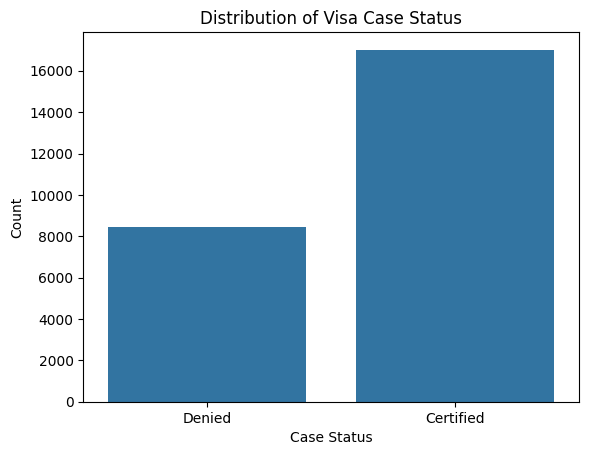

In [15]:
sns.countplot(data=df, x="case_status") # Countplot for target variable
plt.title("Distribution of Visa Case Status")
plt.xlabel("Case Status")
plt.ylabel("Count")
plt.show()

### Observation

The dependent variable is slightly imbalanced.

There are more approved applications than denied applications.

This means that accuracy is not enough to assess the quality of the machine learning models.

Metrics such as recall, precision, and F1-score should also be considered.

###Univariate Analysis

In [16]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()# Separate categorical and numerical columns

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols, numerical_cols

(['case_id',
  'continent',
  'education_of_employee',
  'has_job_experience',
  'requires_job_training',
  'region_of_employment',
  'unit_of_wage',
  'full_time_position',
  'case_status'],
 ['no_of_employees', 'yr_of_estab', 'prevailing_wage'])

In [17]:
cat_cols = [col for col in categorical_cols if col not in ["case_id", "case_status"]] # Remove ID and target from categorical columns for EDA
cat_cols

['continent',
 'education_of_employee',
 'has_job_experience',
 'requires_job_training',
 'region_of_employment',
 'unit_of_wage',
 'full_time_position']

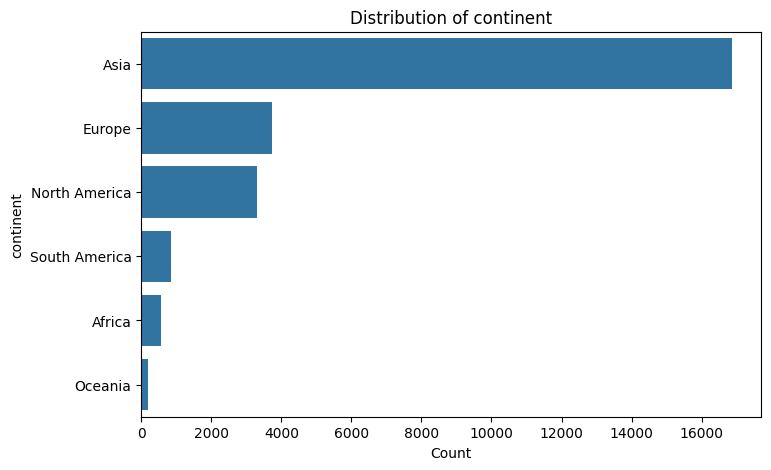

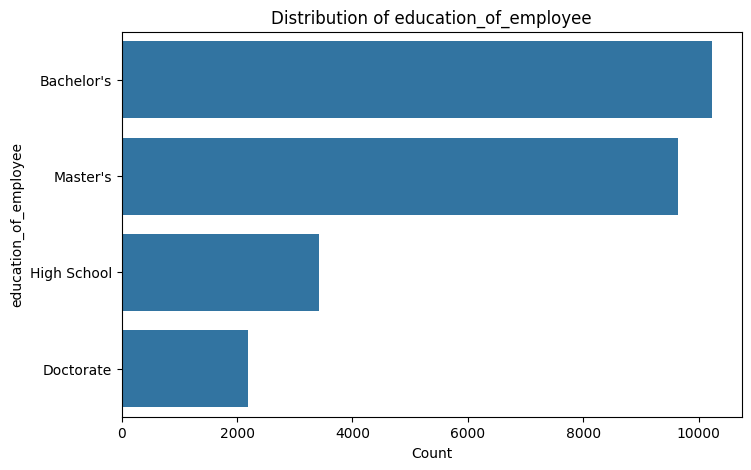

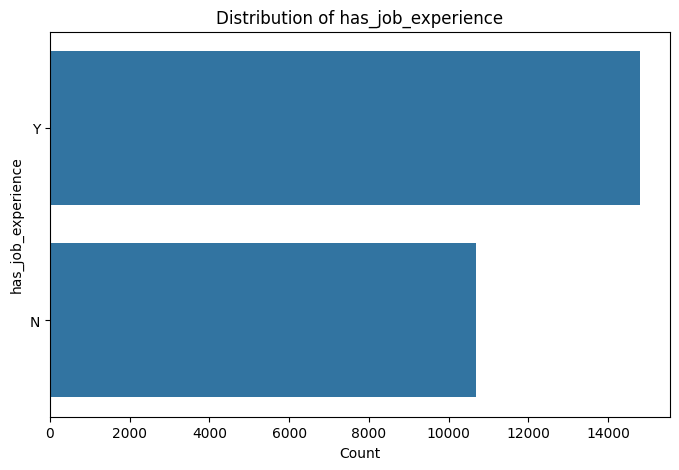

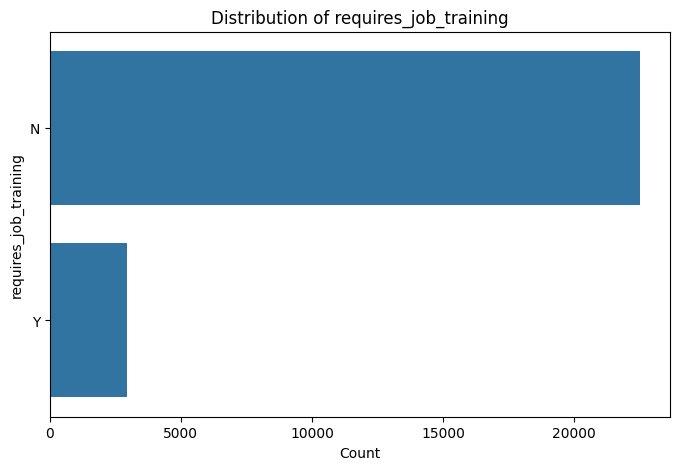

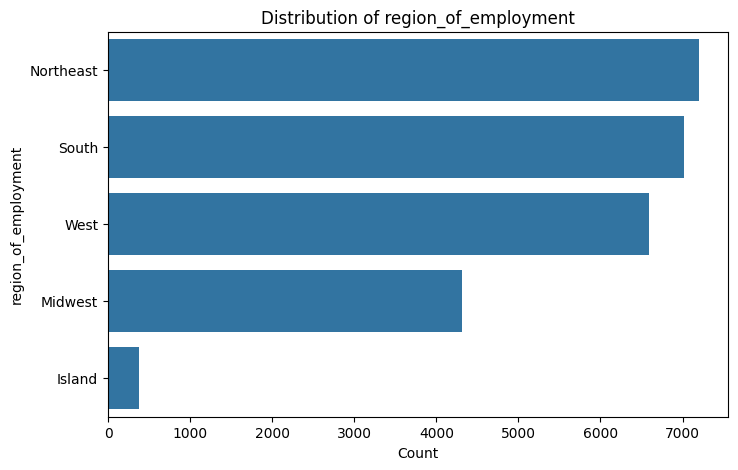

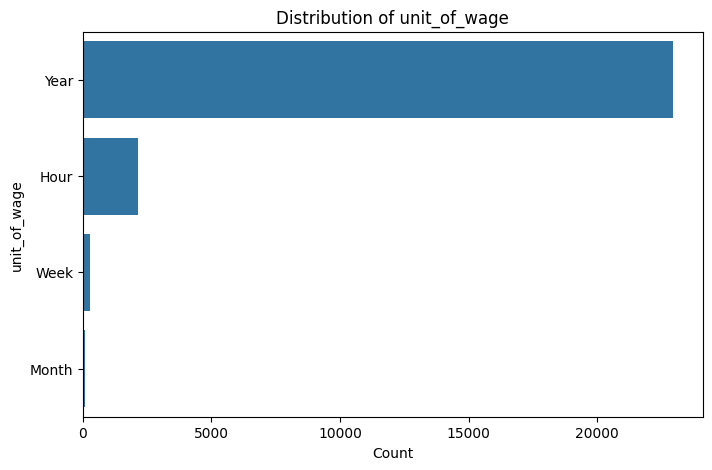

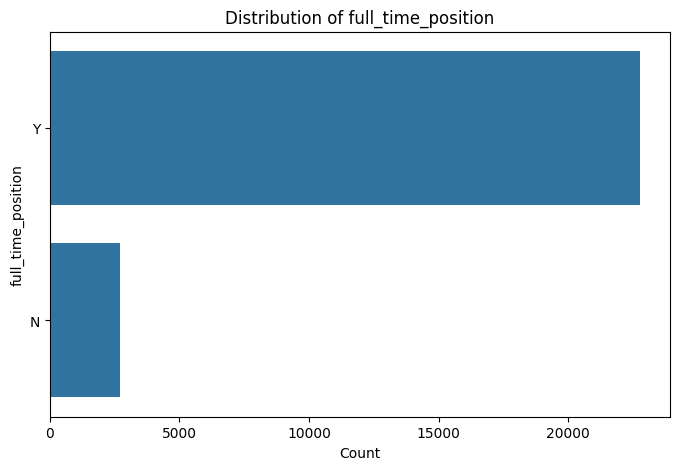

In [18]:
for col in cat_cols: # Countplots for categorical variables
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, y=col, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.show()

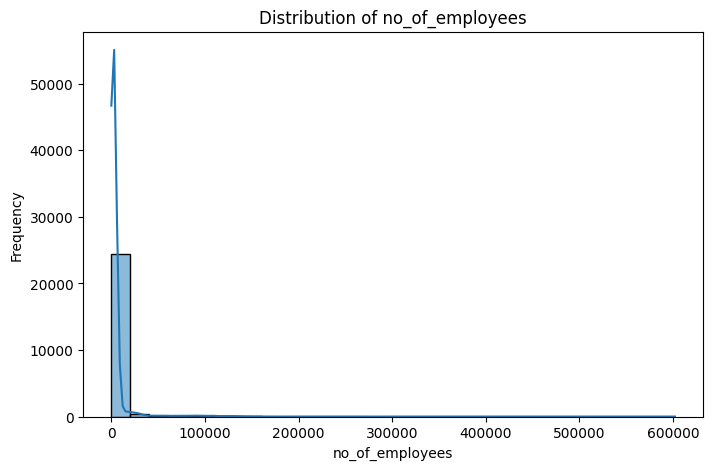

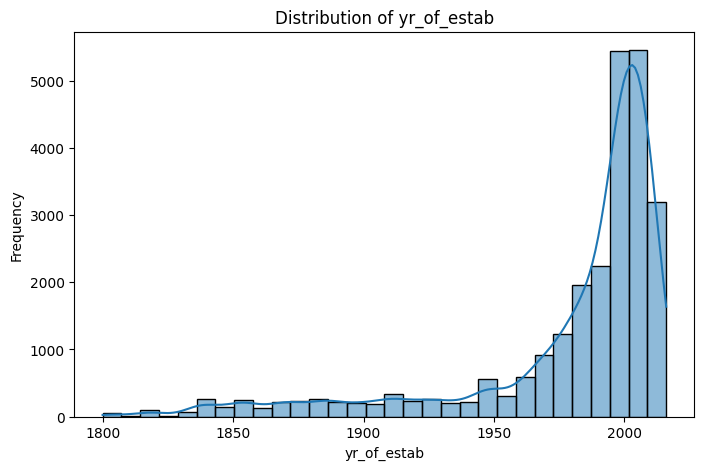

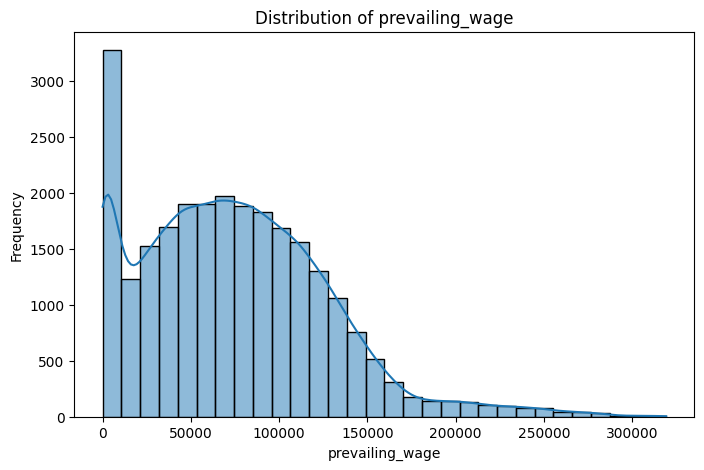

In [19]:
for col in numerical_cols: # Histograms for numerical variables
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

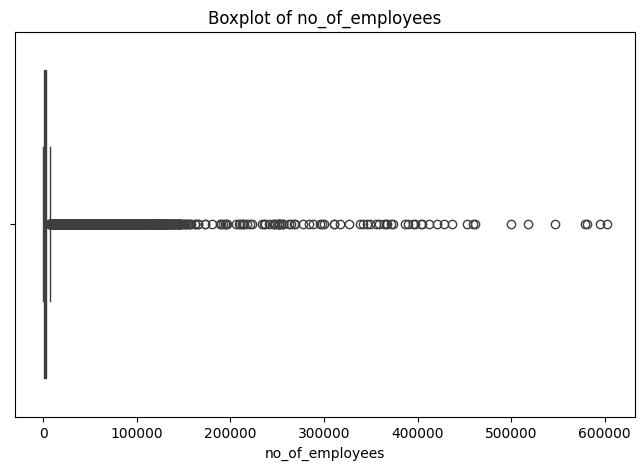

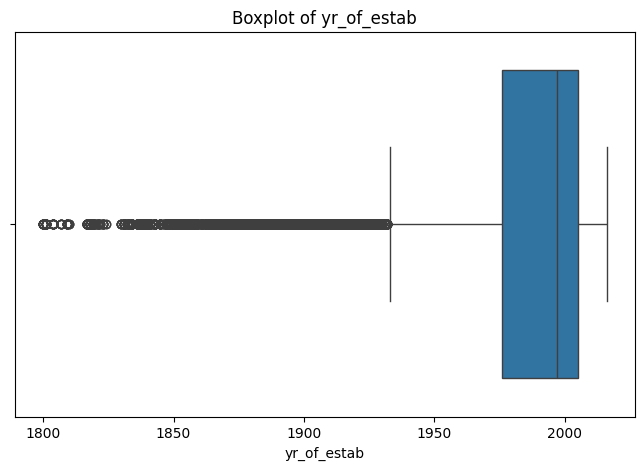

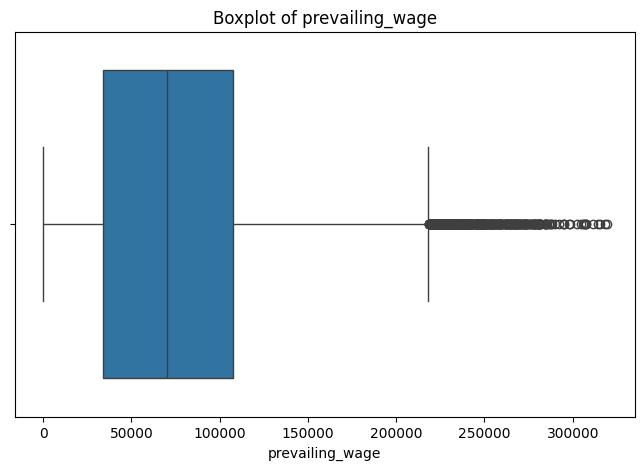

In [20]:
for col in numerical_cols: # Boxplots for numerical variables
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=col)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

#### Univariate Observations

- The majority of examples come from the Asian region.
- People with bachelor’s or master’s degrees account for a major share of applicants.
- Most applicants have employment opportunities.
- Examples typically contain annual salary information.
- Variable `prevailing_wage` exhibits a positive skewness with some high-value outliers.
- Variable `no_of_employees` is extremely skewed, containing some extreme values.
- Variable `no_of_employees` includes negative values, which cannot logically occur and need to be fixed at the data preprocessing stage.
- Variable `case_id` is just an identifier that shouldn’t be used as an explanatory variable.


###Feature Engineering for EDA

In [21]:
df["company_age"] = 2016 - df["yr_of_estab"] # Create company age feature

df[["yr_of_estab", "company_age"]].head() # Dataset appears to have records up to 2016, so we use 2016 as reference year


,yr_of_estab,company_age
0,2007,9
1,2002,14
2,2008,8
3,1897,119
4,2005,11


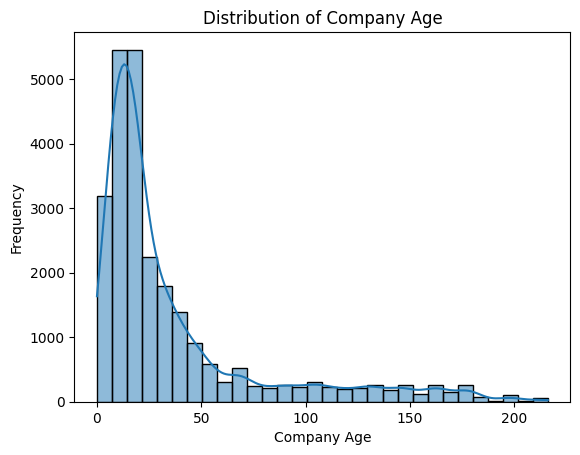

In [22]:
sns.histplot(data=df, x="company_age", kde=True, bins=30) # Distribution of company age
plt.title("Distribution of Company Age")
plt.xlabel("Company Age")
plt.ylabel("Frequency")
plt.show()

###Bivariate Analysis

In [23]:
def certification_rate(data, column):  # Function to calculate certification rate by category
    temp = pd.crosstab(
        data[column],
        data["case_status"],
        normalize="index"
    ) * 100

    temp["Total_Count"] = data[column].value_counts()
    return temp.sort_values(by="Certified", ascending=False)

In [24]:
for col in cat_cols: # Certification rate by categorical columns
    print(f"\nCertification Rate by {col}")
    display(certification_rate(df, col))


Certification Rate by continent


case_status,Certified,Denied,Total_Count
continent,,,
Europe,79.233655,20.766345,3732
Africa,72.050817,27.949183,551
Asia,65.310480,34.689520,16861
Oceania,63.541667,36.458333,192
North America,61.877278,38.122722,3292
South America,57.863850,42.136150,852



Certification Rate by education_of_employee


case_status,Certified,Denied,Total_Count
education_of_employee,,,
Doctorate,87.226277,12.773723,2192
Master's,78.627777,21.372223,9634
Bachelor's,62.214188,37.785812,10234
High School,34.035088,65.964912,3420



Certification Rate by has_job_experience


...

case_status,Certified,Denied,Total_Count
region_of_employment,,,
Midwest,75.528210,24.471790,4307
South,70.015676,29.984324,7017
Northeast,62.904795,37.095205,7195
West,62.253265,37.746735,6586
Island,60.266667,39.733333,375



Certification Rate by unit_of_wage


case_status,Certified,Denied,Total_Count
unit_of_wage,,,
Year,69.885027,30.114973,22962
Week,62.132353,37.867647,272
Month,61.797753,38.202247,89
Hour,34.631433,65.368567,2157



Certification Rate by full_time_position


case_status,Certified,Denied,Total_Count
full_time_position,,,
N,68.526044,31.473956,2707
Y,66.583235,33.416765,22773


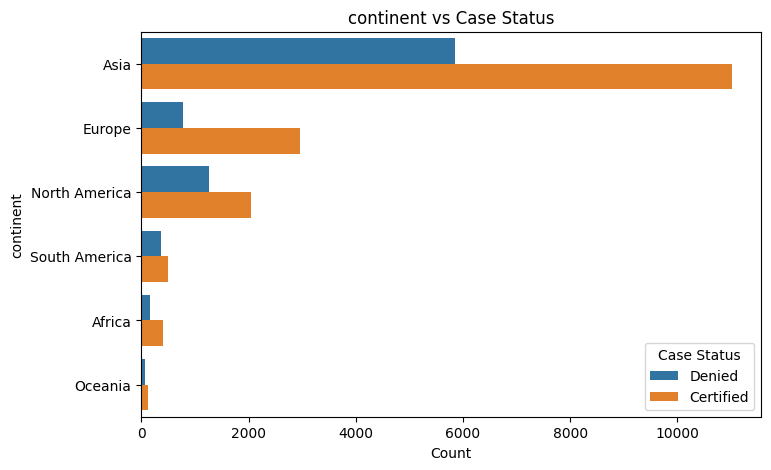

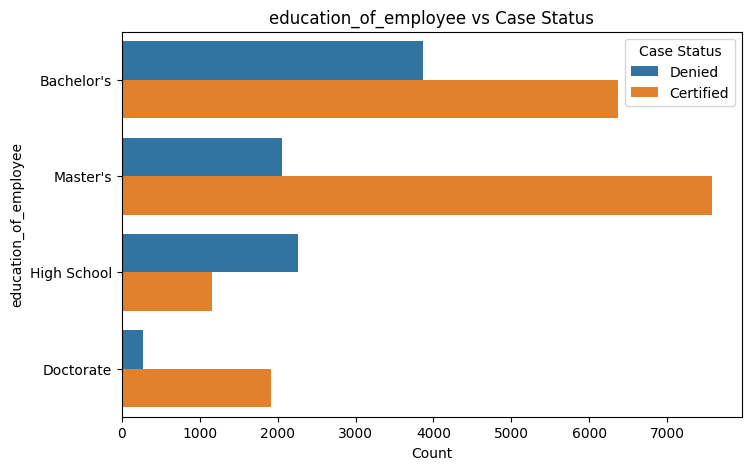

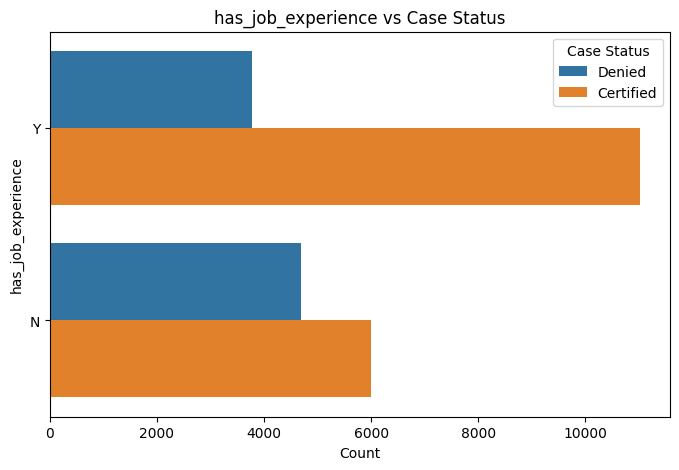

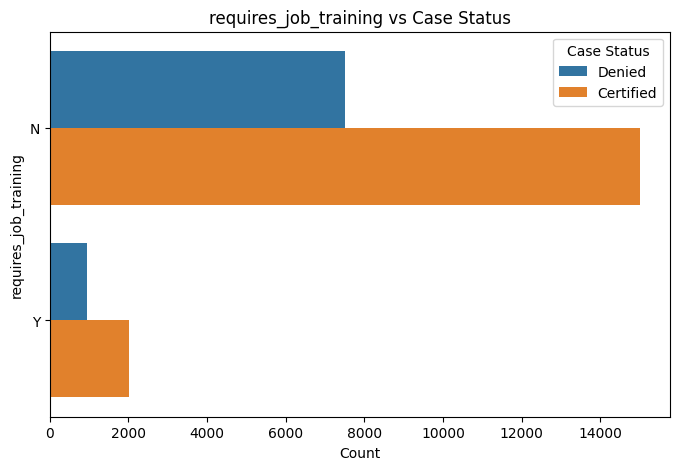

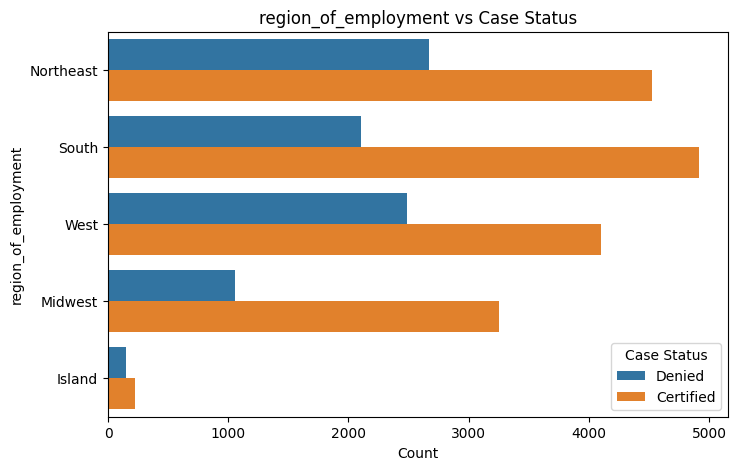

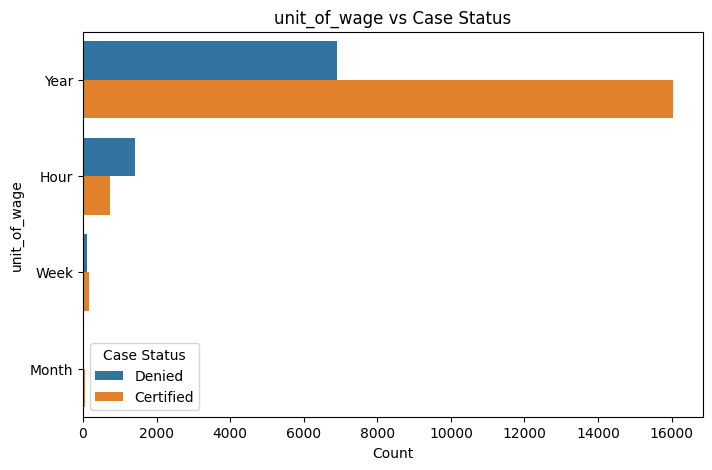

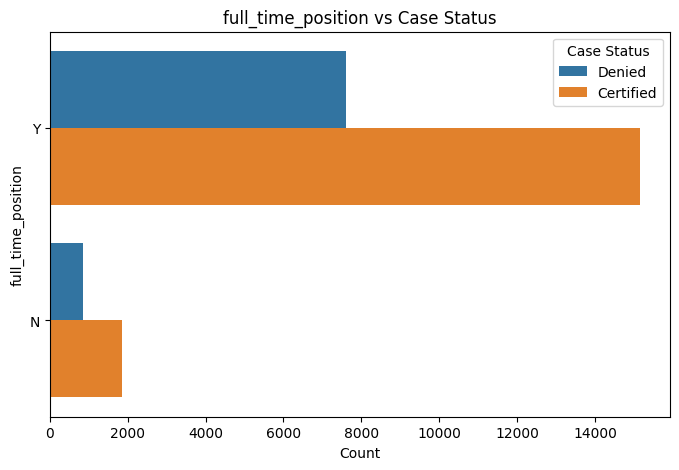

In [25]:
for col in cat_cols: # Barplots: categorical variables vs case_status
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, y=col, hue="case_status", order=df[col].value_counts().index)
    plt.title(f"{col} vs Case Status")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.legend(title="Case Status")
    plt.show()

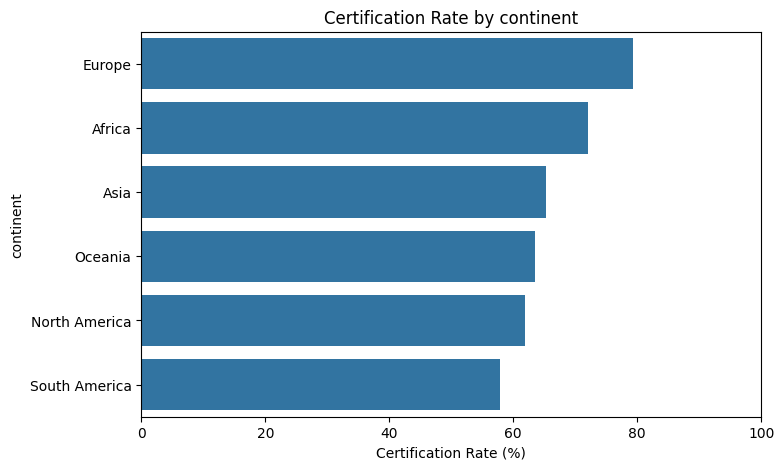

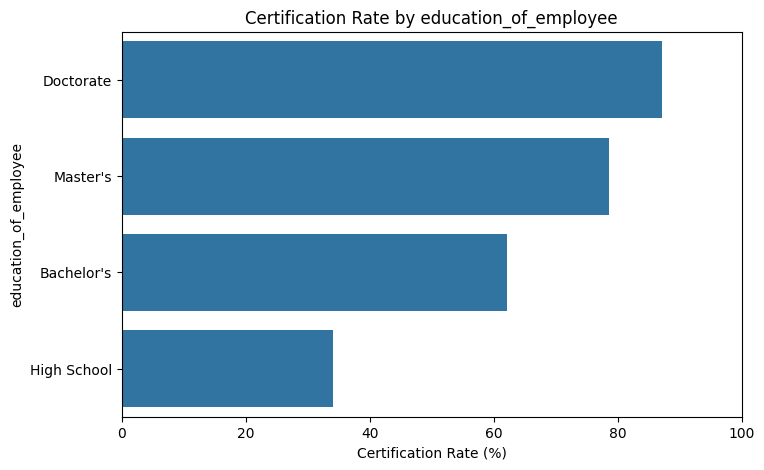

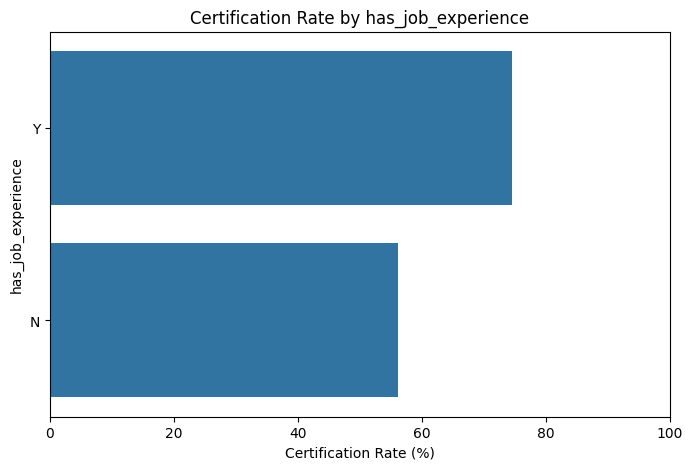

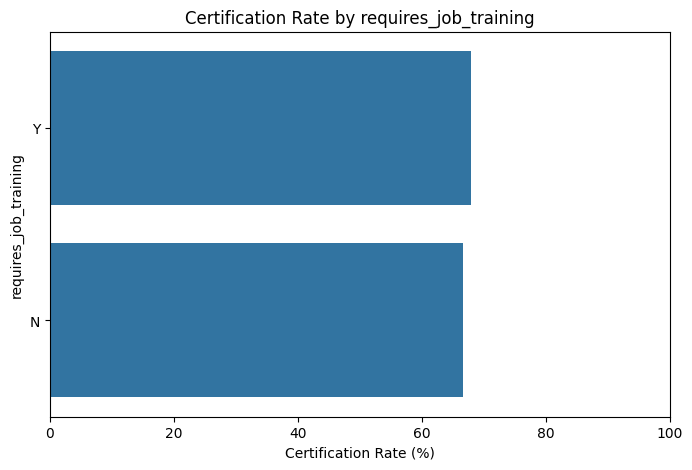

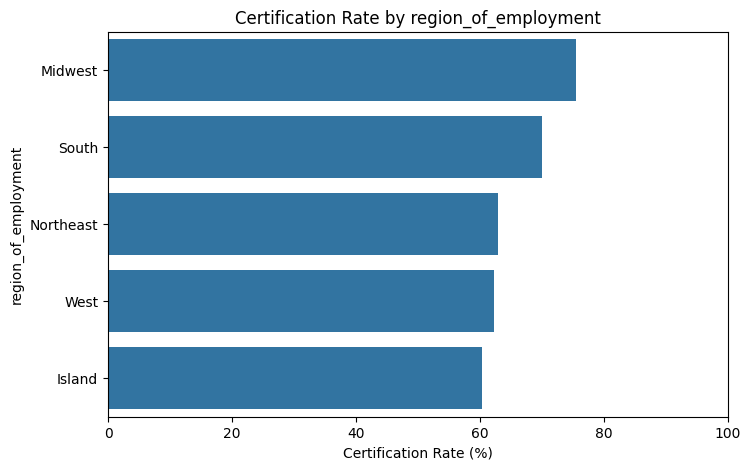

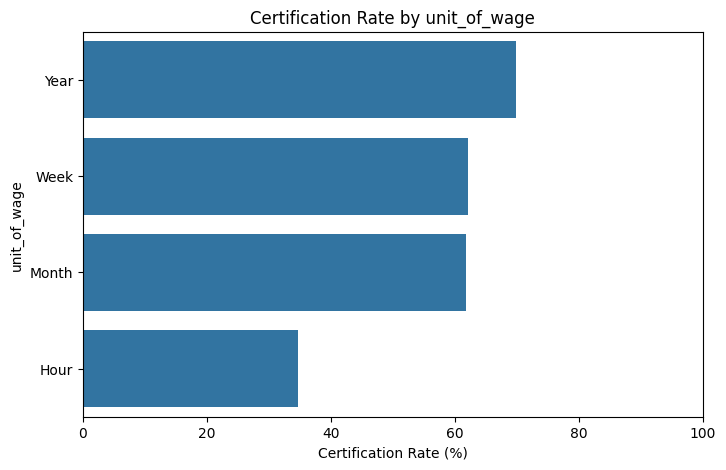

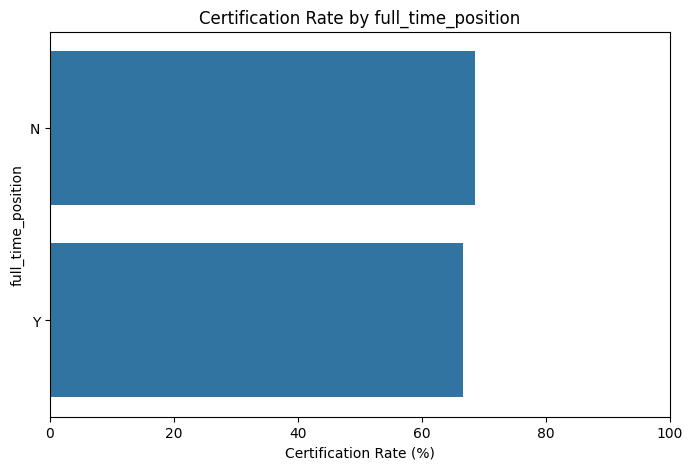

In [26]:
for col in cat_cols: # Certification rate visualizations
    rate_df = df.groupby(col)["case_status"].apply(
        lambda x: (x == "Certified").mean() * 100
    ).reset_index(name="Certification_Rate")

    rate_df = rate_df.sort_values(by="Certification_Rate", ascending=False)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=rate_df, y=col, x="Certification_Rate")
    plt.title(f"Certification Rate by {col}")
    plt.xlabel("Certification Rate (%)")
    plt.ylabel(col)
    plt.xlim(0, 100)
    plt.show()

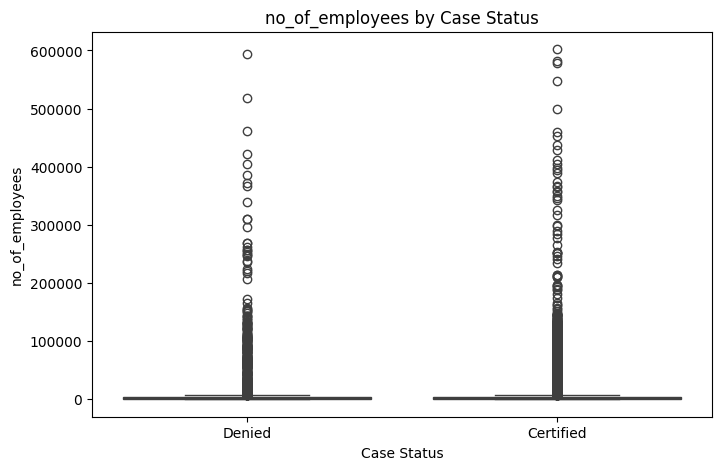

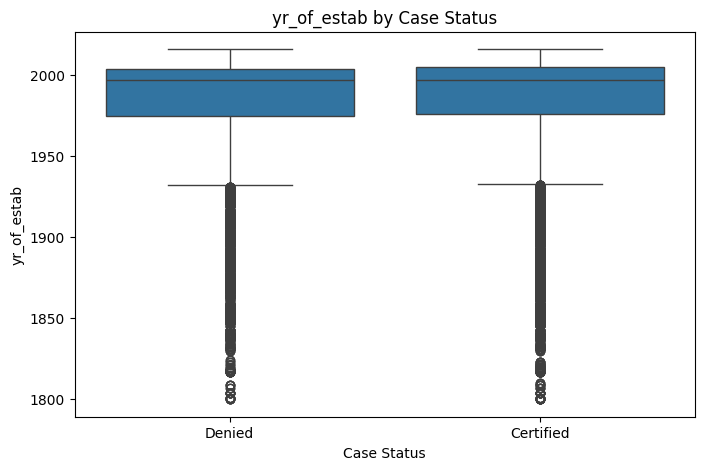

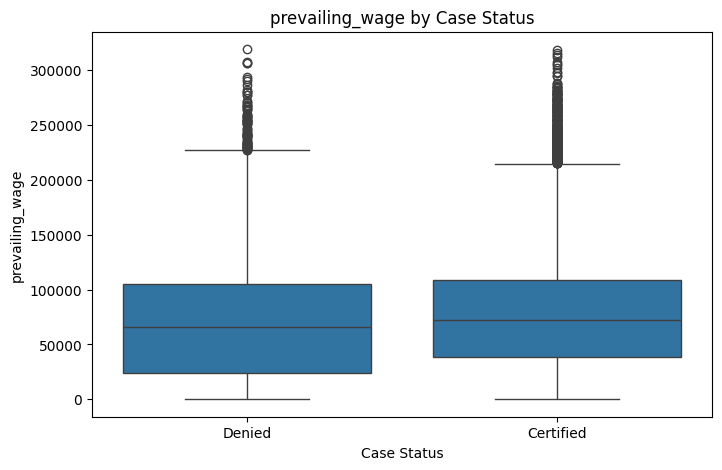

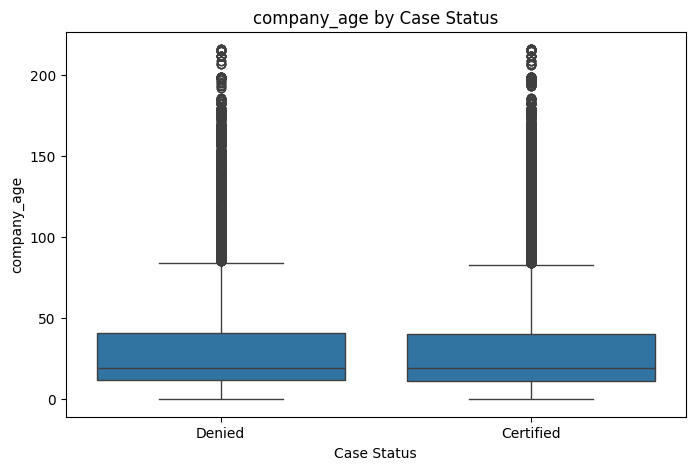

In [27]:
num_cols = ["no_of_employees", "yr_of_estab", "prevailing_wage", "company_age"] # Numerical variables vs target

for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="case_status", y=col)
    plt.title(f"{col} by Case Status")
    plt.xlabel("Case Status")
    plt.ylabel(col)
    plt.show()

In [28]:
df.groupby("case_status")[num_cols].agg(["mean", "median"]).T # Mean and median of numerical variables by case_status

case_status                Certified        Denied
no_of_employees mean     5807.018157   5385.538407
                median   2147.000000   2032.500000
yr_of_estab     mean     1979.666765   1978.893406
                median   1997.000000   1997.000000
prevailing_wage mean    77293.619243  68748.681580
                median  72486.270000  65431.460000
company_age     mean       36.333235     37.106594
                median     19.000000     19.000000

###Correlation Analysis

In [132]:
correlation_cols = ["no_of_employees", "yr_of_estab", "prevailing_wage", "company_age"] # Select numerical columns for correlation analysis.
corr_matrix = df[correlation_cols].corr() # Create a correlation matrix for selected numerical variables.
corr_matrix # Display the correlation matrix.

,no_of_employees,yr_of_estab,prevailing_wage,company_age
no_of_employees,1.000000,-0.017770,-0.009523,0.017770
yr_of_estab,-0.017770,1.000000,0.012342,-1.000000
prevailing_wage,-0.009523,0.012342,1.000000,-0.012342
company_age,0.017770,-1.000000,-0.012342,1.000000


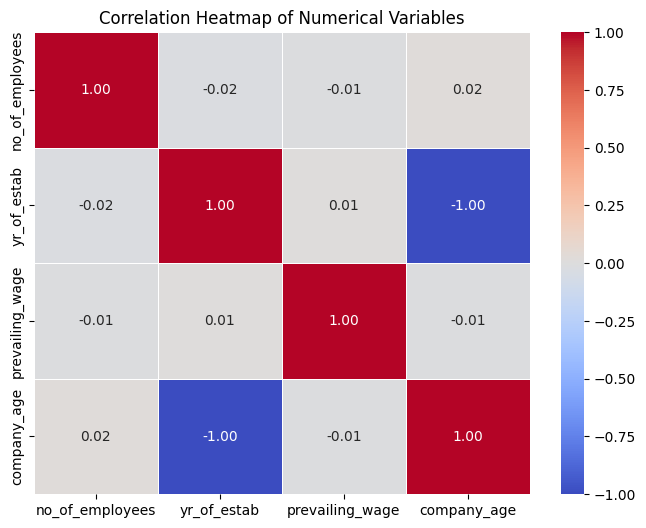

In [133]:
plt.figure(figsize=(8, 6)) # Create a figure for the correlation heatmap.
sns.heatmap(    # Create a heatmap to visualize correlations among numerical variables.
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Variables") # Add title to the heatmap.
plt.show() # Display the heatmap.

In [136]:
## yr_of_estab and company_age will be perfectly negatively correlated

df["company_age"] = 2016 - df["yr_of_estab"] # company_age was created directly from yr_of_estab.

In [137]:
# So for the final modeling dataset, we should keep company_age and drop yr_of_estab.
final_numeric_cols = ["no_of_employees", "prevailing_wage", "company_age"] # Select final numerical variables after feature engineering.
final_corr_matrix = df[final_numeric_cols].corr() # Create a correlation matrix for final numerical variables.
final_corr_matrix  # Display the final numerical correlation matrix.

,no_of_employees,prevailing_wage,company_age
no_of_employees,1.000000,-0.009523,0.017770
prevailing_wage,-0.009523,1.000000,-0.012342
company_age,0.017770,-0.012342,1.000000


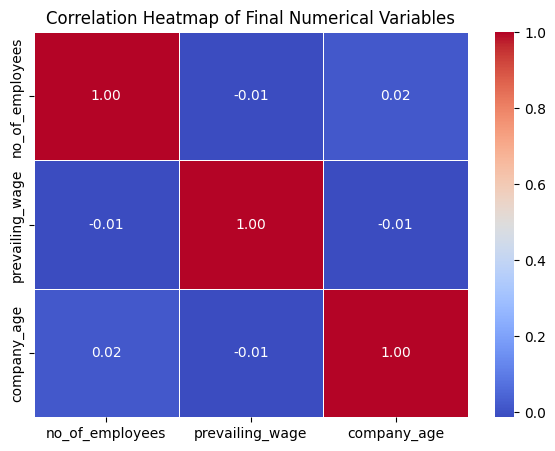

In [138]:
plt.figure(figsize=(7, 5))  # Create a figure for the final correlation heatmap.
sns.heatmap(      # Create a heatmap for final numerical variables.
    final_corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Final Numerical Variables")  # Add title to the heatmap.
plt.show()  # Display the heatmap.

### Correlation Analysis Observation

Correlation analysis was performed on numerical variables to identify relationships and potential multicollinearity.

The initial heatmap showed a perfect negative correlation between `yr_of_estab` and `company_age`, which is expected because `company_age` was directly created from `yr_of_estab`.

To avoid multicollinearity, `yr_of_estab` was dropped and `company_age` was retained for modeling because it is easier to interpret.

The final heatmap using `no_of_employees`, `prevailing_wage`, and `company_age` showed only weak to moderate relationships among the selected numerical variables.

No severe multicollinearity issues were observed among the final numerical predictors.


#### Overall Observations

1. The target variable is moderately imbalanced, with more Certified cases than Denied cases.

2. Education has a strong relationship with visa certification. Applicants with Master's and Doctorate degrees have higher certification rates, while High School applicants have a higher denial rate.

3. Applicants with previous job experience are more likely to be certified than applicants without job experience.

4. Applications with yearly wage units have higher certification rates, while hourly wage applications show higher denial rates.

5. The continent of origin shows differences in certification rates. Some continents have higher approval rates than others.

6. Region of employment also appears to influence certification outcomes. Certain regions show better certification rates.

7. Certified applications tend to have higher prevailing wages compared to denied applications.

8. `prevailing_wage` and `no_of_employees` contain outliers and should be treated carefully during preprocessing.

9. `no_of_employees` contains negative values, which are invalid and should be corrected or treated in the preprocessing stage.

10. `case_id` is a unique identifier and should be dropped before model building because it does not provide predictive information.

###Data Preprocessing

In [29]:
data = df.copy() # Create a copy of the original dataframe so the raw data remains unchanged.
data.head().T # # Display the first few rows to confirm the copied dataset.

,0,1,2,3,4
case_id,EZYV01,EZYV02,EZYV03,EZYV04,EZYV05
continent,Asia,Asia,Asia,Asia,Africa
education_of_employee,High School,Master's,Bachelor's,Bachelor's,Master's
has_job_experience,N,Y,N,N,Y
requires_job_training,N,N,Y,N,N
no_of_employees,14513,2412,44444,98,1082
yr_of_estab,2007,2002,2008,1897,2005
region_of_employment,West,Northeast,West,West,South
prevailing_wage,592.2029,83425.65,122996.86,83434.03,149907.39
unit_of_wage,Hour,Year,Year,Year,Year


In [30]:
data.shape

(25480, 13)

In [31]:
data.isnull().sum() # Check missing values before preprocessing.

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [32]:
data.duplicated().sum() # Check duplicate rows before preprocessing.

np.int64(0)

In [33]:
data["company_age"] = 2016 - data["yr_of_estab"] # Create a new feature called company_age using 2016 as the reference year.
data[["yr_of_estab", "company_age"]].head() # Display the year of establishment and company age to verify the new feature.

,yr_of_estab,company_age
0,2007,9
1,2002,14
2,2008,8
3,1897,119
4,2005,11


In [34]:
(data["no_of_employees"] < 0).sum() # Check how many records have negative employee counts.

np.int64(33)

In [35]:
data.loc[data["no_of_employees"] < 0, "no_of_employees"] = np.nan # Replace negative employee counts with NaN because negative employees are not logically valid.
(data["no_of_employees"] < 0).sum() # Confirm that negative employee counts have been removed.

np.int64(0)

In [36]:
data.drop("case_id", axis=1, inplace=True) # Drop case_id because it is only a unique identifier and has no predictive value.
data.drop("yr_of_estab", axis=1, inplace=True) # Drop yr_of_estab because company_age now represents this information in a more useful way.
data.columns # Display the updated dataframe columns.

Index(['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'region_of_employment',
       'prevailing_wage', 'unit_of_wage', 'full_time_position', 'case_status',
       'company_age'],
      dtype='object')

In [37]:
X = data.drop("case_status", axis=1) # Separate independent variables into X.
y = data["case_status"] # Separate the target variable into y.
y = y.map({"Certified": 1, "Denied": 0}) # Convert target labels into numeric values where Certified is 1 and Denied is 0.
y.head() # Display the first few target values after encoding.

,case_status
0,0
1,1
2,0
3,0
4,1


In [38]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)  # Split the data into training data and temporary data using stratification to preserve target distribution.

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)  # Split the temporary data into validation and test sets equally.

print("Training shape:", X_train.shape) # Check the shape of the training data.

print("Validation shape:", X_val.shape) # Check the shape of the validation data.

print("Test shape:", X_test.shape) # Check the shape of the test data.

Training shape: (17836, 10)
Validation shape: (3822, 10)
Test shape: (3822, 10)


In [39]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100) # Check target distribution in the training set.

print("Validation target distribution:")
print(y_val.value_counts(normalize=True) * 100) # Check target distribution in the validation set.

print("Test target distribution:")
print(y_test.value_counts(normalize=True) * 100) # Check target distribution in the test set.

Training target distribution:
case_status
1    66.791882
0    33.208118
Name: proportion, dtype: float64
Validation target distribution:
case_status
1    66.797488
0    33.202512
Name: proportion, dtype: float64
Test target distribution:
case_status
1    66.771324
0    33.228676
Name: proportion, dtype: float64


In [40]:
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist() # Identify numerical columns from the training data.
categorical_cols = X_train.select_dtypes(include="object").columns.tolist() # Identify categorical columns from the training data.
print("Numerical columns:", numeric_cols) # Display numerical columns.
print("Categorical columns:", categorical_cols) # Display categorical columns.

Numerical columns: ['no_of_employees', 'prevailing_wage', 'company_age']
Categorical columns: ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']


In [41]:
def calculate_iqr_limits(train_data, columns):  # Define a function to calculate IQR-based outlier limits using only training data.
    limits = {}      # Create an empty dictionary to store lower and upper limits.

    for col in columns:  # Loop through each numerical column.

        Q1 = train_data[col].quantile(0.25)  # Calculate the first quartile for the column.

        Q3 = train_data[col].quantile(0.75)  # Calculate the third quartile for the column.

        IQR = Q3 - Q1   # Calculate the interquartile range.

        lower_limit = Q1 - 1.5 * IQR  # Calculate the lower limit for outlier capping.

        upper_limit = Q3 + 1.5 * IQR  # Calculate the upper limit for outlier capping.

        limits[col] = (lower_limit, upper_limit)   # Store the lower and upper limits for the column.

    return limits  # Return the dictionary of limits.

In [42]:
iqr_limits = calculate_iqr_limits(X_train, numeric_cols) # Calculate outlier limits using training data only to avoid data leakage.
iqr_limits # Display the calculated IQR limits.

{'no_of_employees': (np.float64(-2674.0), np.float64(7182.0)),
 'prevailing_wage': (np.float64(-76436.05125000002), np.float64(218270.47875)),
 'company_age': (np.float64(-32.5), np.float64(83.5))}

In [43]:
def cap_outliers(dataframe, limits):  # Define a function to cap outliers using limits calculated from training data.

    capped_df = dataframe.copy() # Create a copy of the dataframe to avoid modifying the original split directly.

    for col, (lower_limit, upper_limit) in limits.items(): # Loop through each column and its lower and upper limits.

        capped_df[col] = capped_df[col].clip(lower=lower_limit)  # Cap values below the lower limit.

        capped_df[col] = capped_df[col].clip(upper=upper_limit) # Cap values above the upper limit.

    return capped_df # Return the capped dataframe.

In [44]:
X_train_capped = cap_outliers(X_train, iqr_limits) # Apply outlier capping to the training data.
X_val_capped = cap_outliers(X_val, iqr_limits) # Apply the same training-data-based limits to the validation data.
X_test_capped = cap_outliers(X_test, iqr_limits) # Apply the same training-data-based limits to the test data.

In [45]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
) # Create a numerical preprocessing pipeline with median imputation.

try:   # Try creating OneHotEncoder using the newer sparse_output argument.

        categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]
    ) # Create categorical preprocessing pipeline with most frequent imputation and one-hot encoding.

except TypeError:  # Use this block if the Colab sklearn version uses the older sparse argument.

        categorical_transformer = Pipeline(    # Create categorical preprocessing pipeline with older OneHotEncoder syntax.
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse=False))
        ]
    )

In [46]:
preprocessor = ColumnTransformer(   # Create the full preprocessing transformer for numerical and categorical columns.
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [47]:
X_train_processed = preprocessor.fit_transform(X_train_capped) # Fit the preprocessor only on training data to avoid data leakage.
X_val_processed = preprocessor.transform(X_val_capped) # Transform validation data using the preprocessor fitted on training data.
X_test_processed = preprocessor.transform(X_test_capped) # Transform test data using the preprocessor fitted on training data.

In [48]:
encoded_cat_cols = preprocessor.named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(categorical_cols) # Get the names of one-hot encoded categorical features.
final_feature_names = numeric_cols + encoded_cat_cols.tolist() # Combine numerical and encoded categorical feature names.
X_train_processed = pd.DataFrame(X_train_processed, columns=final_feature_names, index=X_train.index) # Convert processed training array into a dataframe.
X_val_processed = pd.DataFrame(X_val_processed, columns=final_feature_names, index=X_val.index) # Convert processed validation array into a dataframe.
X_test_processed = pd.DataFrame(X_test_processed, columns=final_feature_names, index=X_test.index) # Convert processed test array into a dataframe.

In [49]:
print("Processed training shape:", X_train_processed.shape) # Check processed training data shape.
print("Processed validation shape:", X_val_processed.shape) # Check processed validation data shape.
print("Processed test shape:", X_test_processed.shape) # Check processed test data shape.

Processed training shape: (17836, 28)
Processed validation shape: (3822, 28)
Processed test shape: (3822, 28)


In [50]:
print("Missing values in processed training data:", X_train_processed.isnull().sum().sum()) # Confirm that processed training data has no missing values.
print("Missing values in processed validation data:", X_val_processed.isnull().sum().sum()) # Confirm that processed validation data has no missing values.
print("Missing values in processed test data:", X_test_processed.isnull().sum().sum()) # Confirm that processed test data has no missing values.

Missing values in processed training data: 0
Missing values in processed validation data: 0
Missing values in processed test data: 0


In [51]:
X_train_processed.head().T # Display the first few rows of processed training data.

,19643,17663,14342,8854,7811
no_of_employees,893.00,1850.00,1475.00,2877.00,523.00
prevailing_wage,141964.49,127273.02,77724.07,60777.57,50633.23
company_age,20.00,17.00,17.00,41.00,13.00
continent_Africa,0.00,0.00,0.00,0.00,0.00
continent_Asia,0.00,1.00,1.00,1.00,1.00
continent_Europe,1.00,0.00,0.00,0.00,0.00
continent_North America,0.00,0.00,0.00,0.00,0.00
continent_Oceania,0.00,0.00,0.00,0.00,0.00
continent_South America,0.00,0.00,0.00,0.00,0.00
education_of_employee_Bachelor's,0.00,0.00,1.00,0.00,1.00


### Summary

The following preprocessing steps were completed:

1. Created a copy of the original dataset to preserve raw data.
2. Created a new feature called `company_age` from `yr_of_estab`.
3. Replaced invalid negative values in `no_of_employees` with missing values.
4. Dropped `case_id` because it is only an identifier.
5. Dropped `yr_of_estab` because `company_age` captures the same information more directly.
6. Encoded the target variable `case_status`, where Certified = 1 and Denied = 0.
7. Split the data into training, validation, and test sets using stratification.
8. Calculated outlier limits using only the training data.
9. Applied the same outlier treatment rules to validation and test data.
10. Imputed missing numerical values using the training median.
11. Imputed missing categorical values using the most frequent category from training data.
12. One-hot encoded categorical variables.
13. Fitted preprocessing only on training data to prevent data leakage.

This prepared dataset is now ready for model building on original data.

###Model Building - Original Data

In [52]:
print(y_train.value_counts(normalize=True) * 100) # Print the class distribution in the training target variable.
print("Since the target variable is moderately imbalanced, F1-score will be used as an important evaluation metric.") # Print a short note about the selected metric.

case_status
1    66.791882
0    33.208118
Name: proportion, dtype: float64
Since the target variable is moderately imbalanced, F1-score will be used as an important evaluation metric.


In [53]:
models_original = {} # Create an empty dictionary to store all original-data models.
models_original["Decision Tree"] = DecisionTreeClassifier(random_state=42) # Add a Decision Tree model to the dictionary.
models_original["Bagging Classifier"] = BaggingClassifier(random_state=42) # Add a Bagging Classifier model to the dictionary.
models_original["Random Forest"] = RandomForestClassifier(random_state=42) # Add a Random Forest model to the dictionary.
models_original["Extra Trees"] = ExtraTreesClassifier(random_state=42) # Add an Extra Trees model to the dictionary.
models_original["AdaBoost"] = AdaBoostClassifier(random_state=42) # Add an AdaBoost model to the dictionary.
models_original["Gradient Boosting"] = GradientBoostingClassifier(random_state=42) # Add a Gradient Boosting model to the dictionary.

In [54]:
def evaluate_model(model, X_train, y_train, X_val, y_val): # Define a function to evaluate classification models.

    model.fit(X_train, y_train) # Fit the model on the training data.

    train_preds = model.predict(X_train)  # Predict target values for the training data.

    val_preds = model.predict(X_val) # Predict target values for the validation data.

    train_probs = model.predict_proba(X_train)[:, 1] # Predict probabilities for the positive class on training data.

    val_probs = model.predict_proba(X_val)[:, 1] # Predict probabilities for the positive class on validation data.

    train_accuracy = accuracy_score(y_train, train_preds) # Calculate training accuracy.

    val_accuracy = accuracy_score(y_val, val_preds) # Calculate validation accuracy.

    train_precision = precision_score(y_train, train_preds) # Calculate training precision.

    val_precision = precision_score(y_val, val_preds) # Calculate validation precision.

    train_recall = recall_score(y_train, train_preds) # Calculate training recall.

    val_recall = recall_score(y_val, val_preds) # Calculate validation recall.

    train_f1 = f1_score(y_train, train_preds)  # Calculate training F1-score.

    val_f1 = f1_score(y_val, val_preds) # Calculate validation F1-score.

    train_roc_auc = roc_auc_score(y_train, train_probs) # Calculate training ROC-AUC score.

    val_roc_auc = roc_auc_score(y_val, val_probs) # Calculate validation ROC-AUC score.

    return {    # Return all calculated metrics as a dictionary.
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train Precision": train_precision,
        "Validation Precision": val_precision,
        "Train Recall": train_recall,
        "Validation Recall": val_recall,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Train ROC-AUC": train_roc_auc,
        "Validation ROC-AUC": val_roc_auc
    }

In [55]:
original_results = [] # Create an empty list to store model performance results.
for model_name, model in models_original.items():  # Loop through each model name and model object.

    result = evaluate_model(model, X_train_processed, y_train, X_val_processed, y_val) # Evaluate the current model using the evaluation function.

    result["Model"] = model_name # Add the model name to the result dictionary.

    original_results.append(result) # Append the result dictionary to the results list.

In [56]:
original_results_df = pd.DataFrame(original_results)  # Convert the list of model results into a dataframe.
original_results_df = original_results_df[  # Reorder columns to show model name first.
    [
        "Model",
        "Train Accuracy",
        "Validation Accuracy",
        "Train Precision",
        "Validation Precision",
        "Train Recall",
        "Validation Recall",
        "Train F1",
        "Validation F1",
        "Train ROC-AUC",
        "Validation ROC-AUC"
    ]
]
original_results_df = original_results_df.sort_values(by="Validation F1", ascending=False) # Sort models by validation F1-score in descending order.
original_results_df.T # Display the model performance comparison table.

,5,4,2,3,1,0
Model,Gradient Boosting,AdaBoost,Random Forest,Extra Trees,Bagging Classifier,Decision Tree
Train Accuracy,0.75712,0.738899,1.0,1.0,0.984862,1.0
Validation Accuracy,0.743328,0.729723,0.722135,0.70539,0.704605,0.657509
Train Precision,0.784252,0.762594,1.0,1.0,0.992221,1.0
Validation Precision,0.773486,0.755892,0.768455,0.757488,0.771548,0.74373
Train Recall,0.877865,0.884412,1.0,1.0,0.985058,1.0
Validation Recall,0.87074,0.879358,0.835879,0.82217,0.792401,0.743439
Train F1,0.828422,0.818998,1.0,1.0,0.988627,1.0
Validation F1,0.819237,0.812964,0.80075,0.788505,0.781836,0.743585
Train ROC-AUC,0.796494,0.773265,1.0,1.0,0.998554,1.0


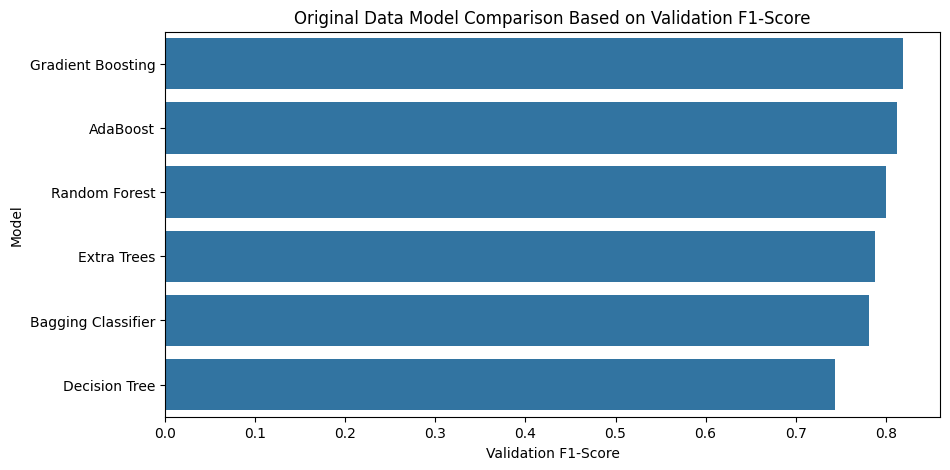

In [57]:
plt.figure(figsize=(10, 5)) # Create a bar plot to compare validation F1-scores.
sns.barplot(data=original_results_df, x="Validation F1", y="Model") # Plot validation F1-score for each model.
plt.title("Original Data Model Comparison Based on Validation F1-Score") # Add chart title.
plt.xlabel("Validation F1-Score") # Add x-axis label.
plt.ylabel("Model") # Add y-axis label.
plt.show() # Display the plot.

In [58]:
best_original_model_name = original_results_df.iloc[0]["Model"] # Select the best model name based on highest validation F1-score.
print("Best model on original data:", best_original_model_name) # Print the best model name.
best_original_model = models_original[best_original_model_name] # Get the best model object from the models dictionary.
best_original_val_preds = best_original_model.predict(X_val_processed) # Predict validation data using the best original-data model.
print(classification_report(y_val, best_original_val_preds, target_names=["Denied", "Certified"])) # Print the classification report for the best original-data model.

Best model on original data: Gradient Boosting
              precision    recall  f1-score   support

      Denied       0.65      0.49      0.56      1269
   Certified       0.77      0.87      0.82      2553

    accuracy                           0.74      3822
   macro avg       0.71      0.68      0.69      3822
weighted avg       0.73      0.74      0.73      3822



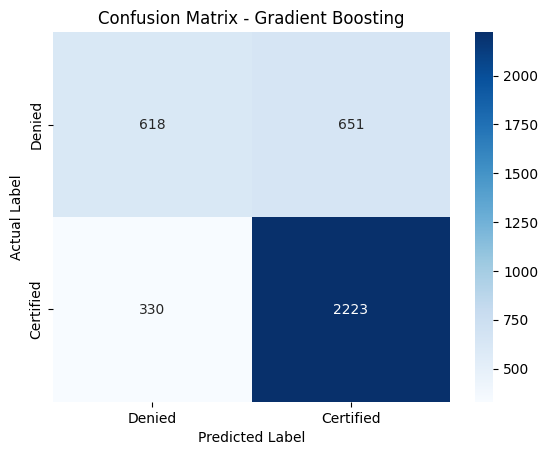

In [59]:
cm = confusion_matrix(y_val, best_original_val_preds) # Create confusion matrix for the best original-data model.
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"]) # Create a heatmap for the confusion matrix.
plt.title(f"Confusion Matrix - {best_original_model_name}") # Add chart title.
plt.xlabel("Predicted Label") # Add x-axis label.
plt.ylabel("Actual Label") # Add y-axis label.
plt.show() # Display the plot.

### Conclusion

Models that were created using the original preprocessed data are as follows:

1. Decision Tree
2. Bagging Classifier
3. Random Forest
4. Extra Trees
5. AdaBoost
6. Gradient Boosting

The rubric states that there should be 5 models, but here are 6 models since the models need to be compared in a better way.

### Metric Selection

The target variable has a moderate imbalance since the number of Certified cases exceeds that of Denied cases. Thus, just accuracy would not suffice here. Hence, F1-score is chosen as an important metric because it balances precision and recall.

### Model Performance Remarks

- The Decision Tree tends to perform extremely well in training data but can easily overfit.
- Bagging and Random Forest decrease overfitting by integrating different decision trees.
- Extra Trees add even more randomness.
- AdaBoost and Gradient Boosting use sequential tree building. These are models where a tree is created one by one.
- The best model from original data should be selected based on validation F1-score and validation recall, ROC-AUC.

###Model Building - Oversampled Data

In [60]:
print("Before oversampling:") # Check the class distribution before oversampling.
print(y_train.value_counts()) # Print the count of each class in the original training target.

Before oversampling:
case_status
1    11913
0     5923
Name: count, dtype: int64


In [64]:
ros = RandomOverSampler(random_state=42) # Create a RandomOverSampler object with a fixed random_state for reproducibility.
X_train_over, y_train_over = ros.fit_resample(X_train_processed, y_train) # Apply oversampling only on the training data.
print("Oversampled X_train shape:", X_train_over.shape) # Check the shape of the oversampled training features.
print("Oversampled y_train shape:", y_train_over.shape) # Check the shape of the oversampled training target.

Oversampled X_train shape: (23826, 28)
Oversampled y_train shape: (23826,)


In [65]:
print("After oversampling:") # Check the class distribution after oversampling.
print(y_train_over.value_counts()) # Print the count of each class after oversampling.

After oversampling:
case_status
0    11913
1    11913
Name: count, dtype: int64


In [66]:
models_oversampled = {} # Create an empty dictionary to store oversampled-data models.
models_oversampled["Decision Tree"] = DecisionTreeClassifier(random_state=42) # Add a Decision Tree model to the dictionary.
models_oversampled["Bagging Classifier"] = BaggingClassifier(random_state=42) # Add a Bagging Classifier model to the dictionary.
models_oversampled["Random Forest"] = RandomForestClassifier(random_state=42) # Add a Random Forest model to the dictionary.
models_oversampled["Extra Trees"] = ExtraTreesClassifier(random_state=42)  # Add an Extra Trees model to the dictionary.
models_oversampled["AdaBoost"] = AdaBoostClassifier(random_state=42) # Add an AdaBoost model to the dictionary.
models_oversampled["Gradient Boosting"] = GradientBoostingClassifier(random_state=42) # Add a Gradient Boosting model to the dictionary.

In [67]:
def evaluate_model(model, X_train, y_train, X_val, y_val): # Define a function to evaluate a classification model.

    model.fit(X_train, y_train)  # Fit the model on the training data.

    train_preds = model.predict(X_train) # Predict labels for the training data.

    val_preds = model.predict(X_val) # Predict labels for the validation data.

    train_probs = model.predict_proba(X_train)[:, 1] # Predict probabilities for the positive class on training data.

    val_probs = model.predict_proba(X_val)[:, 1] # Predict probabilities for the positive class on validation data.

    train_accuracy = accuracy_score(y_train, train_preds) # Calculate training accuracy.

    val_accuracy = accuracy_score(y_val, val_preds) # Calculate validation accuracy.

    train_precision = precision_score(y_train, train_preds) # Calculate training precision.

    val_precision = precision_score(y_val, val_preds) # Calculate validation precision.

    train_recall = recall_score(y_train, train_preds) # Calculate training recall.

    val_recall = recall_score(y_val, val_preds) # Calculate validation recall.

    train_f1 = f1_score(y_train, train_preds) # Calculate training F1-score.

    val_f1 = f1_score(y_val, val_preds) # Calculate validation F1-score.

    train_roc_auc = roc_auc_score(y_train, train_probs)  # Calculate training ROC-AUC score.

    val_roc_auc = roc_auc_score(y_val, val_probs) # Calculate validation ROC-AUC score.

    return {              # Return all metrics as a dictionary.
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train Precision": train_precision,
        "Validation Precision": val_precision,
        "Train Recall": train_recall,
        "Validation Recall": val_recall,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Train ROC-AUC": train_roc_auc,
        "Validation ROC-AUC": val_roc_auc
    }

In [68]:
oversampled_results = [] # Create an empty list to store oversampled model results.

for model_name, model in models_oversampled.items():  # Loop through each model name and model object.

    result = evaluate_model(model, X_train_over, y_train_over, X_val_processed, y_val) # Evaluate the current model using oversampled training data and original validation data.

    result["Model"] = model_name # Add the model name to the result dictionary.

    oversampled_results.append(result) # Append the result dictionary to the oversampled results list.

In [76]:
oversampled_results_df = pd.DataFrame(oversampled_results) # Convert the oversampled model results list into a dataframe.

oversampled_results_df = oversampled_results_df[    # Reorder the columns to show the model name first.
    [
        "Model",
        "Train Accuracy",
        "Validation Accuracy",
        "Train Precision",
        "Validation Precision",
        "Train Recall",
        "Validation Recall",
        "Train F1",
        "Validation F1",
        "Train ROC-AUC",
        "Validation ROC-AUC"
    ]
]

oversampled_results_df = oversampled_results_df.sort_values(by="Validation F1", ascending=False) # Sort the results by validation F1-score in descending order.

oversampled_results_df.T # Display the oversampled model performance table.

,3,2,5,1,4,0
Model,Extra Trees,Random Forest,Gradient Boosting,Bagging Classifier,AdaBoost,Decision Tree
Train Accuracy,1.0,0.999958,0.721061,0.988416,0.693948,1.0
Validation Accuracy,0.712977,0.709053,0.710623,0.692308,0.694662,0.653061
Train Precision,1.0,1.0,0.711849,0.99701,0.680437,1.0
Validation Precision,0.761871,0.776796,0.813883,0.786041,0.798193,0.738438
Train Recall,1.0,0.999916,0.742802,0.97977,0.731386,1.0
Validation Recall,0.829612,0.792009,0.734822,0.741089,0.726596,0.744222
Train F1,1.0,0.999958,0.726996,0.988315,0.704992,1.0
Validation F1,0.7943,0.784329,0.772334,0.762903,0.760714,0.741319
Train ROC-AUC,1.0,1.0,0.797774,0.999595,0.770363,1.0


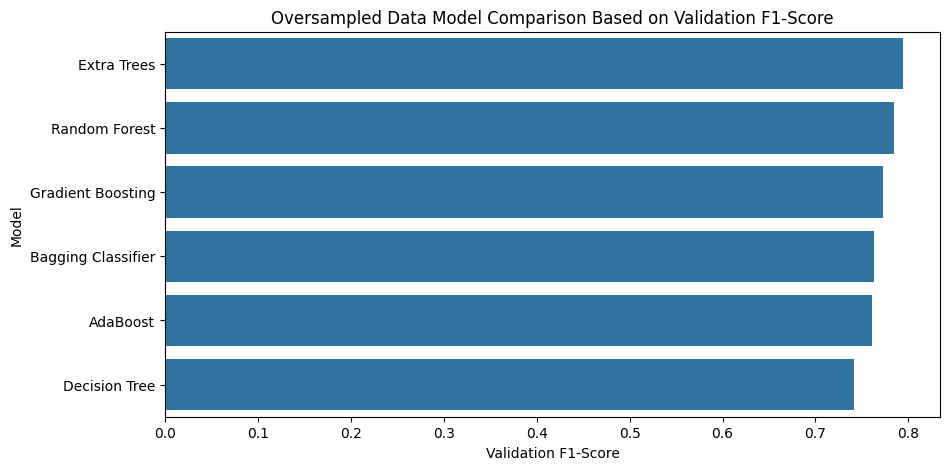

In [71]:
plt.figure(figsize=(10, 5)) # Create a bar plot to compare validation F1-scores for oversampled models.
sns.barplot(data=oversampled_results_df, x="Validation F1", y="Model") # Plot validation F1-score for each oversampled model.
plt.title("Oversampled Data Model Comparison Based on Validation F1-Score") # Add a title to the chart.
plt.xlabel("Validation F1-Score")
plt.ylabel("Model")
plt.show()

In [72]:
best_oversampled_model_name = oversampled_results_df.iloc[0]["Model"] # Select the best oversampled model name based on the highest validation F1-score.
print("Best model on oversampled data:", best_oversampled_model_name) # Print the best oversampled model name.
best_oversampled_model = models_oversampled[best_oversampled_model_name] # Get the best oversampled model object from the dictionary.
best_oversampled_val_preds = best_oversampled_model.predict(X_val_processed) # Predict validation labels using the best oversampled model.
print(classification_report(y_val, best_oversampled_val_preds, target_names=["Denied", "Certified"])) # Print the classification report for the best oversampled model.

Best model on oversampled data: Extra Trees
              precision    recall  f1-score   support

      Denied       0.58      0.48      0.53      1269
   Certified       0.76      0.83      0.79      2553

    accuracy                           0.71      3822
   macro avg       0.67      0.65      0.66      3822
weighted avg       0.70      0.71      0.70      3822



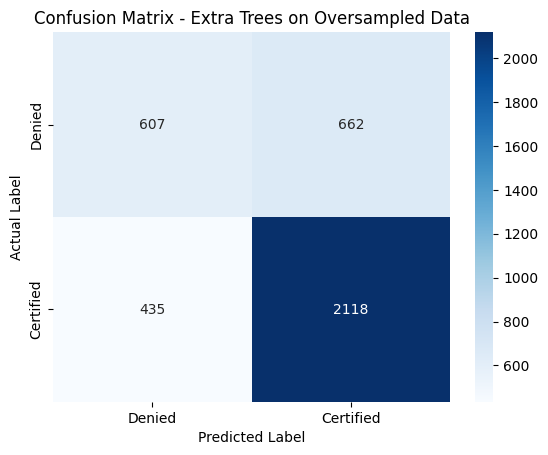

In [73]:
cm_over = confusion_matrix(y_val, best_oversampled_val_preds) # Create a confusion matrix for the best oversampled model.
sns.heatmap(cm_over, annot=True, fmt="d", cmap="Blues", xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"]) # Create a heatmap for the confusion matrix.
plt.title(f"Confusion Matrix - {best_oversampled_model_name} on Oversampled Data") # Add a title to the confusion matrix chart.
plt.xlabel("Predicted Label") # Add a label to the x-axis.
plt.ylabel("Actual Label") # Add a label to the y-axis.
plt.show() # Display the confusion matrix chart.

In [75]:
oversampled_results_df["Data Type"] = "Oversampled Data" # Add a column to identify these results as oversampled-data results.
oversampled_results_df.T # Display the final oversampled results dataframe.

,3,2,5,1,4,0
Model,Extra Trees,Random Forest,Gradient Boosting,Bagging Classifier,AdaBoost,Decision Tree
Train Accuracy,1.0,0.999958,0.721061,0.988416,0.693948,1.0
Validation Accuracy,0.712977,0.709053,0.710623,0.692308,0.694662,0.653061
Train Precision,1.0,1.0,0.711849,0.99701,0.680437,1.0
Validation Precision,0.761871,0.776796,0.813883,0.786041,0.798193,0.738438
Train Recall,1.0,0.999916,0.742802,0.97977,0.731386,1.0
Validation Recall,0.829612,0.792009,0.734822,0.741089,0.726596,0.744222
Train F1,1.0,0.999958,0.726996,0.988315,0.704992,1.0
Validation F1,0.7943,0.784329,0.772334,0.762903,0.760714,0.741319
Train ROC-AUC,1.0,1.0,0.797774,0.999595,0.770363,1.0


###Conclusion

Oversampling was done only on the training set in order not to introduce data leakage. Validation and test sets remained the same in order to have realistic results.

Models built on oversampled training data:

Decision Tree

Bagging Classifier

Random Forest

Extra Trees

AdaBoost

Gradient Boosting

As per the rubric requirements, 5 models must be created but 6 models are being created in order to compare them.

###Performance Comments

By using oversampling, we make sure that the training dataset is balanced between Certified and Denied class. It might be helpful in making the model understand the minority class better.

After oversampling, the minority class recall might improve due to increased examples of the denied applications in the training data. However, since we duplicate minority class observations during oversampling, we might increase the risk of overfitting, especially for tree-based models.

Selection criteria for the best model after oversampling include mostly validation F1 score, however, validation recall, precision and ROC-AUC must be considered as well.

###Model Building - Undersampled Data

In [77]:
print("Before undersampling:") # Check the class distribution before undersampling.
print(y_train.value_counts()) # Print the count of each class in the original training target.

Before undersampling:
case_status
1    11913
0     5923
Name: count, dtype: int64


In [78]:
rus = RandomUnderSampler(random_state=42) # Create a RandomUnderSampler object with a fixed random_state for reproducibility.
X_train_under, y_train_under = rus.fit_resample(X_train_processed, y_train) # Apply undersampling only on the training data.
print("Undersampled X_train shape:", X_train_under.shape) # Check the shape of the undersampled training features.
print("Undersampled y_train shape:", y_train_under.shape) # Check the shape of the undersampled training target.

Undersampled X_train shape: (11846, 28)
Undersampled y_train shape: (11846,)


In [79]:
print("After undersampling:") # Check the class distribution after undersampling.
print(y_train_under.value_counts()) # Print the count of each class after undersampling.

After undersampling:
case_status
0    5923
1    5923
Name: count, dtype: int64


In [80]:
models_undersampled = {} # Create an empty dictionary to store undersampled-data models.
models_undersampled["Decision Tree"] = DecisionTreeClassifier(random_state=42) # Add a Decision Tree model to the dictionary.
models_undersampled["Bagging Classifier"] = BaggingClassifier(random_state=42) # Add a Bagging Classifier model to the dictionary.
models_undersampled["Random Forest"] = RandomForestClassifier(random_state=42) # Add a Random Forest model to the dictionary.
models_undersampled["Extra Trees"] = ExtraTreesClassifier(random_state=42) # Add an Extra Trees model to the dictionary.
models_undersampled["AdaBoost"] = AdaBoostClassifier(random_state=42) # Add an AdaBoost model to the dictionary.
models_undersampled["Gradient Boosting"] = GradientBoostingClassifier(random_state=42) # Add a Gradient Boosting model to the dictionary.

In [81]:
def evaluate_model(model, X_train, y_train, X_val, y_val):  # Define a function to evaluate a classification model.

    model.fit(X_train, y_train) # Fit the model on the training data.

    train_preds = model.predict(X_train) # Predict labels for the training data.

    val_preds = model.predict(X_val) # Predict labels for the validation data.

    train_probs = model.predict_proba(X_train)[:, 1] # Predict probabilities for the positive class on training data.

    val_probs = model.predict_proba(X_val)[:, 1] # Predict probabilities for the positive class on validation data.

    train_accuracy = accuracy_score(y_train, train_preds) # Calculate training accuracy.

    val_accuracy = accuracy_score(y_val, val_preds) # Calculate validation accuracy.

    train_precision = precision_score(y_train, train_preds) # Calculate training precision.

    val_precision = precision_score(y_val, val_preds) # Calculate validation precision.

    train_recall = recall_score(y_train, train_preds) # Calculate training recall.

    val_recall = recall_score(y_val, val_preds) # Calculate validation recall.

    train_f1 = f1_score(y_train, train_preds) # Calculate training F1-score.

    val_f1 = f1_score(y_val, val_preds) # Calculate validation F1-score.

    train_roc_auc = roc_auc_score(y_train, train_probs) # Calculate training ROC-AUC score.

    val_roc_auc = roc_auc_score(y_val, val_probs) # Calculate validation ROC-AUC score.

    return {      # Return all metrics as a dictionary.
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train Precision": train_precision,
        "Validation Precision": val_precision,
        "Train Recall": train_recall,
        "Validation Recall": val_recall,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Train ROC-AUC": train_roc_auc,
        "Validation ROC-AUC": val_roc_auc
    }

In [82]:
undersampled_results = [] # Create an empty list to store undersampled model results.

for model_name, model in models_undersampled.items(): # Loop through each model name and model object.

    result = evaluate_model(model, X_train_under, y_train_under, X_val_processed, y_val) # Evaluate the current model using undersampled training data and original validation data.

    result["Model"] = model_name # Add the model name to the result dictionary.

    undersampled_results.append(result) # Append the result dictionary to the undersampled results list.

In [84]:
undersampled_results_df = pd.DataFrame(undersampled_results) # Convert the undersampled model results list into a dataframe.
undersampled_results_df = undersampled_results_df[  # Reorder the columns to show the model name first.
    [
        "Model",
        "Train Accuracy",
        "Validation Accuracy",
        "Train Precision",
        "Validation Precision",
        "Train Recall",
        "Validation Recall",
        "Train F1",
        "Validation F1",
        "Train ROC-AUC",
        "Validation ROC-AUC"
    ]
]
undersampled_results_df = undersampled_results_df.sort_values(by="Validation F1", ascending=False) # Sort the results by validation F1-score in descending order.
undersampled_results_df.T # Display the undersampled model performance table.

,5,4,2,3,1,0
Model,Gradient Boosting,AdaBoost,Random Forest,Extra Trees,Bagging Classifier,Decision Tree
Train Accuracy,0.721087,0.695256,1.0,1.0,0.978389,1.0
Validation Accuracy,0.709314,0.689691,0.677656,0.673469,0.641287,0.616431
Train Precision,0.714637,0.686022,1.0,1.0,0.99116,1.0
Validation Precision,0.817342,0.799912,0.807066,0.799175,0.801223,0.76577
Train Recall,0.736113,0.720074,1.0,1.0,0.965389,1.0
Validation Recall,0.72738,0.714062,0.679984,0.682726,0.615746,0.613396
Train F1,0.725216,0.702636,1.0,1.0,0.978105,1.0
Validation F1,0.769741,0.754553,0.738095,0.736375,0.696346,0.681166
Train ROC-AUC,0.79718,0.772234,1.0,1.0,0.998301,1.0


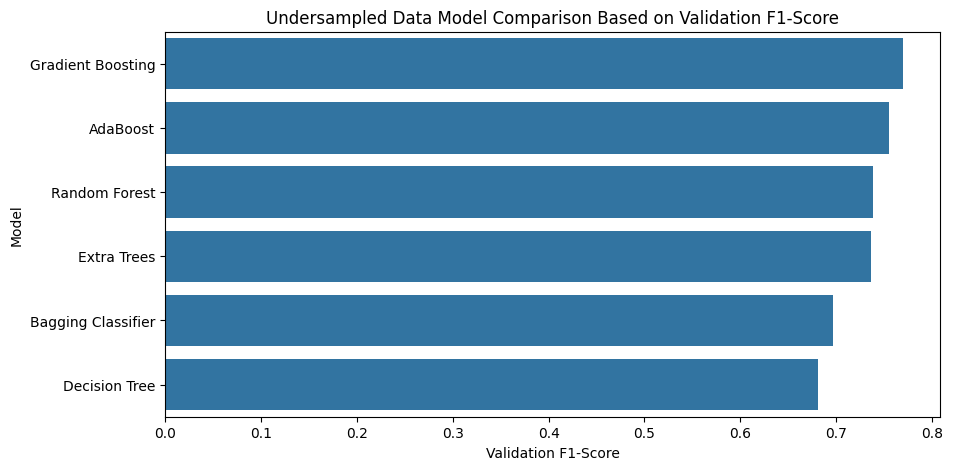

In [85]:
plt.figure(figsize=(10, 5)) # Create a bar plot to compare validation F1-scores for undersampled models.
sns.barplot(data=undersampled_results_df, x="Validation F1", y="Model") # Plot validation F1-score for each undersampled model.
plt.title("Undersampled Data Model Comparison Based on Validation F1-Score") # Add a title to the chart.
plt.xlabel("Validation F1-Score")
plt.ylabel("Model")
Plt.show()

In [86]:
best_undersampled_model_name = undersampled_results_df.iloc[0]["Model"] # Select the best undersampled model name based on the highest validation F1-score.
print("Best model on undersampled data:", best_undersampled_model_name) # Print the best undersampled model name.
best_undersampled_model = models_undersampled[best_undersampled_model_name] # Get the best undersampled model object from the dictionary.
best_undersampled_val_preds = best_undersampled_model.predict(X_val_processed) #Predict validation labels using the best undersampled model.
print(classification_report(y_val, best_undersampled_val_preds, target_names=["Denied", "Certified"])) # Print the classification report for the best undersampled model.

Best model on undersampled data: Gradient Boosting
              precision    recall  f1-score   support

      Denied       0.55      0.67      0.61      1269
   Certified       0.82      0.73      0.77      2553

    accuracy                           0.71      3822
   macro avg       0.68      0.70      0.69      3822
weighted avg       0.73      0.71      0.72      3822



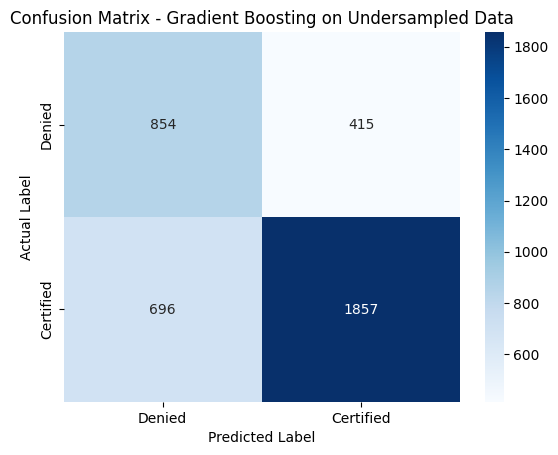

In [87]:
cm_under = confusion_matrix(y_val, best_undersampled_val_preds) # Create a confusion matrix for the best undersampled model.
sns.heatmap(cm_under, annot=True, fmt="d", cmap="Blues", xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"]) # Create a heatmap for the confusion matrix.
plt.title(f"Confusion Matrix - {best_undersampled_model_name} on Undersampled Data") # Add a title to the confusion matrix chart.
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show() # Display the confusion matrix chart.

In [89]:
undersampled_results_df["Data Type"] = "Undersampled Data" # Add a column to identify these results as undersampled-data results.
undersampled_results_df.T # Display the final undersampled results dataframe.

,5,4,2,3,1,0
Model,Gradient Boosting,AdaBoost,Random Forest,Extra Trees,Bagging Classifier,Decision Tree
Train Accuracy,0.721087,0.695256,1.0,1.0,0.978389,1.0
Validation Accuracy,0.709314,0.689691,0.677656,0.673469,0.641287,0.616431
Train Precision,0.714637,0.686022,1.0,1.0,0.99116,1.0
Validation Precision,0.817342,0.799912,0.807066,0.799175,0.801223,0.76577
Train Recall,0.736113,0.720074,1.0,1.0,0.965389,1.0
Validation Recall,0.72738,0.714062,0.679984,0.682726,0.615746,0.613396
Train F1,0.725216,0.702636,1.0,1.0,0.978105,1.0
Validation F1,0.769741,0.754553,0.738095,0.736375,0.696346,0.681166
Train ROC-AUC,0.79718,0.772234,1.0,1.0,0.998301,1.0


###Conclusion

Undersampling was applied only to the training data to avoid data leakage. The validation and test sets were kept unchanged.

The following models were built on undersampled training data:

1. Decision Tree
2. Bagging Classifier
3. Random Forest
4. Extra Trees
5. AdaBoost
6. Gradient Boosting

Although the rubric asks for 5 models, 6 models were built for better comparison.

### Performance Comments

Under-sampling will balance both classes by decreasing the numbers in Certified category in the training dataset.

This will possibly help the model focus more on the Denied category. But since under-sampling will discard the majority class, it may lead to loss of relevant information.

That is why undersampled models can enhance recall in terms of denied applications but may sacrifice accuracy and stability.

The optimal undersampled model needs to be selected based on validation F1 score as well as other metrics like recall, precision, and ROC-AUC.

###Model Performance Improvement using Hyperparameter Tuning.

We will tune 3 models with RandomizedSearchCV:

Random Forest

Extra Trees

Gradient Boosting

This could be a good choice since tree-based models tend to perform well when tuned and can identify non-linear relationships well

In [90]:
print("F1-score is used as the tuning metric because it balances precision and recall.") # Print a note explaining the tuning metric.
print("RandomizedSearchCV will be used to improve selected model performance.") # Print a note explaining why tuning is being done.

F1-score is used as the tuning metric because it balances precision and recall.
RandomizedSearchCV will be used to improve selected model performance.


In [91]:
X_tune_train = X_train_processed # Create training feature data for tuning using original processed training data.
y_tune_train = y_train # Create training target data for tuning using original training target.
X_tune_val = X_val_processed # Create validation feature data for final tuned-model comparison.
y_tune_val = y_val # Create validation target data for final tuned-model comparison.

In [92]:
rf_model = RandomForestClassifier(random_state=42) # Create the Random Forest model with a fixed random_state.
et_model = ExtraTreesClassifier(random_state=42) # Create the Extra Trees model with a fixed random_state.
gb_model = GradientBoostingClassifier(random_state=42) # Create the Gradient Boosting model with a fixed random_state.

In [93]:
rf_param_grid = {  # Define the hyperparameter search space for Random Forest.

    "n_estimators": [100, 150, 200, 300], # Try different numbers of trees.

    "max_depth": [None, 5, 10, 15, 20], # Try different maximum depths for the trees.

    "min_samples_split": [2, 5, 10], # Try different minimum samples required to split a node.

    "min_samples_leaf": [1, 2, 4], # Try different minimum samples required at a leaf node.

    "max_features": ["sqrt", "log2"] # Try different numbers of features considered at each split.
}

In [94]:
et_param_grid = {   # Define the hyperparameter search space for Extra Trees.

    "n_estimators": [100, 150, 200, 300],  # Try different numbers of trees.

    "max_depth": [None, 5, 10, 15, 20],  # Try different maximum depths for the trees.

    "min_samples_split": [2, 5, 10], # Try different minimum samples required to split a node.

    "min_samples_leaf": [1, 2, 4], # Try different minimum samples required at a leaf node.

    "max_features": ["sqrt", "log2"] # Try different numbers of features considered at each split.
}

In [95]:
gb_param_grid = {  # Define the hyperparameter search space for Gradient Boosting.

    "n_estimators": [100, 150, 200], # Try different numbers of boosting stages.

    "learning_rate": [0.01, 0.05, 0.1, 0.2], # Try different learning rates.

    "max_depth": [2, 3, 4, 5], # Try different maximum depths for individual trees.

    "min_samples_split": [2, 5, 10], # Try different minimum samples required to split a node.

    "min_samples_leaf": [1, 2, 4],  # Try different minimum samples required at a leaf node.

    "subsample": [0.7, 0.8, 0.9, 1.0]  # Try different subsample rates for stochastic gradient boosting.
}

In [96]:
rf_random_search = RandomizedSearchCV(  # Create RandomizedSearchCV object for Random Forest.

    estimator=rf_model,  # Pass the Random Forest model.

    param_distributions=rf_param_grid, # Pass the Random Forest hyperparameter grid.

    n_iter=20, # Set the number of random combinations to try.

    scoring="f1", # Use F1-score as the metric for tuning.

    cv=3, # Use 3-fold cross-validation.

    n_jobs=-1, # Use all available CPU cores.

    random_state=42, # Set random_state for reproducible results.

    verbose=1  # Print progress while tuning.
)

In [97]:
et_random_search = RandomizedSearchCV( # Create RandomizedSearchCV object for Extra Trees.

    estimator=et_model,  # Pass the Extra Trees model.

    param_distributions=et_param_grid, # Pass the Extra Trees hyperparameter grid.

    n_iter=20, # Set the number of random combinations to try.

    scoring="f1", # Use F1-score as the metric for tuning.

    cv=3, # Use 3-fold cross-validation.

    n_jobs=-1, # Use all available CPU cores.

    random_state=42,  # Set random_state for reproducible results.

    verbose=1  # Print progress while tuning.
)

In [98]:
gb_random_search = RandomizedSearchCV(  # Create RandomizedSearchCV object for Gradient Boosting.

    estimator=gb_model,  # Pass the Gradient Boosting model.

    param_distributions=gb_param_grid, # Pass the Gradient Boosting hyperparameter grid.

    n_iter=20,   # Set the number of random combinations to try.

    scoring="f1",  # Use F1-score as the metric for tuning.

    cv=3, # Use 3-fold cross-validation.

    n_jobs=-1,  # Use all available CPU cores.

    random_state=42,  # Set random_state for reproducible results.

    verbose=1  # Print progress while tuning.
)

In [99]:
rf_random_search.fit(X_tune_train, y_tune_train) # Fit the Random Forest randomized search on the training data.
print("Best Random Forest Parameters:", rf_random_search.best_params_) # Print the best Random Forest parameters.
print("Best Random Forest CV F1-score:", rf_random_search.best_score_) # Print the best cross-validation F1-score for Random Forest.

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Random Forest Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10}
Best Random Forest CV F1-score: 0.8252360506177171


In [100]:
et_random_search.fit(X_tune_train, y_tune_train) # Fit the Extra Trees randomized search on the training data.
print("Best Extra Trees Parameters:", et_random_search.best_params_) # Print the best Extra Trees parameters.
print("Best Extra Trees CV F1-score:", et_random_search.best_score_) # Print the best cross-validation F1-score for Extra Trees.

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Extra Trees Parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10}
Best Extra Trees CV F1-score: 0.8257037784617328


In [101]:
gb_random_search.fit(X_tune_train, y_tune_train)  # Fit the Gradient Boosting randomized search on the training data.
print("Best Gradient Boosting Parameters:", gb_random_search.best_params_) # Print the best Gradient Boosting parameters.
print("Best Gradient Boosting CV F1-score:", gb_random_search.best_score_) # Print the best cross-validation F1-score for Gradient Boosting.

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Gradient Boosting Parameters: {'subsample': 0.8, 'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 5, 'learning_rate': 0.01}
Best Gradient Boosting CV F1-score: 0.8248136765385734


In [102]:
tuned_models = {} # Create a dictionary to store the best tuned models.
tuned_models["Tuned Random Forest"] = rf_random_search.best_estimator_ # Store the best Random Forest model.
tuned_models["Tuned Extra Trees"] = et_random_search.best_estimator_  # Store the best Extra Trees model.
tuned_models["Tuned Gradient Boosting"] = gb_random_search.best_estimator_  # Store the best Gradient Boosting model.

In [103]:
def evaluate_tuned_model(model, X_train, y_train, X_val, y_val):  # Define a function to evaluate tuned models.

    train_preds = model.predict(X_train) # Predict labels for the training data.

    val_preds = model.predict(X_val) # Predict labels for the validation data.

    train_probs = model.predict_proba(X_train)[:, 1] # Predict probabilities for the positive class on training data.

    val_probs = model.predict_proba(X_val)[:, 1] # Predict probabilities for the positive class on validation data.

    train_accuracy = accuracy_score(y_train, train_preds) # Calculate training accuracy.

    val_accuracy = accuracy_score(y_val, val_preds) # Calculate validation accuracy.

    train_precision = precision_score(y_train, train_preds) # Calculate training precision.

    val_precision = precision_score(y_val, val_preds) # Calculate validation precision.

    train_recall = recall_score(y_train, train_preds) # Calculate training recall.

    val_recall = recall_score(y_val, val_preds) # Calculate validation recall.

    train_f1 = f1_score(y_train, train_preds) # Calculate training F1-score.

    val_f1 = f1_score(y_val, val_preds) # Calculate validation F1-score.

    train_roc_auc = roc_auc_score(y_train, train_probs) # Calculate training ROC-AUC score.

    val_roc_auc = roc_auc_score(y_val, val_probs) # Calculate validation ROC-AUC score.

    return {  # Return all metrics as a dictionary.
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train Precision": train_precision,
        "Validation Precision": val_precision,
        "Train Recall": train_recall,
        "Validation Recall": val_recall,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Train ROC-AUC": train_roc_auc,
        "Validation ROC-AUC": val_roc_auc
    }

In [106]:
tuned_results = [] # Create an empty list to store tuned model results.

for model_name, model in tuned_models.items(): # Loop through each tuned model name and model object.

    result = evaluate_tuned_model(model, X_tune_train, y_tune_train, X_tune_val, y_tune_val) # Evaluate the current tuned model.

    result["Model"] = model_name # Add the model name to the result dictionary.

    tuned_results.append(result) # Append the result dictionary to the tuned results list.

In [107]:
tuned_results_df = pd.DataFrame(tuned_results) # Convert tuned model results into a dataframe.
tuned_results_df = tuned_results_df[  # Reorder the columns to show model name first.
    [
        "Model",
        "Train Accuracy",
        "Validation Accuracy",
        "Train Precision",
        "Validation Precision",
        "Train Recall",
        "Validation Recall",
        "Train F1",
        "Validation F1",
        "Train ROC-AUC",
        "Validation ROC-AUC"
    ]
]
tuned_results_df = tuned_results_df.sort_values(by="Validation F1", ascending=False) # Sort tuned model results by validation F1-score.
tuned_results_df.T # Display tuned model comparison table.

,2,1,0
Model,Tuned Gradient Boosting,Tuned Extra Trees,Tuned Random Forest
Train Accuracy,0.748542,0.761045,0.764297
Validation Accuracy,0.736525,0.745683,0.74516
Train Precision,0.754698,0.783938,0.785075
Validation Precision,0.745086,0.77137,0.770284
Train Recall,0.923781,0.886594,0.891043
Validation Recall,0.920486,0.880141,0.881316
Train F1,0.830723,0.832112,0.834709
Validation F1,0.82355,0.822173,0.822068
Train ROC-AUC,0.792702,0.812667,0.820838


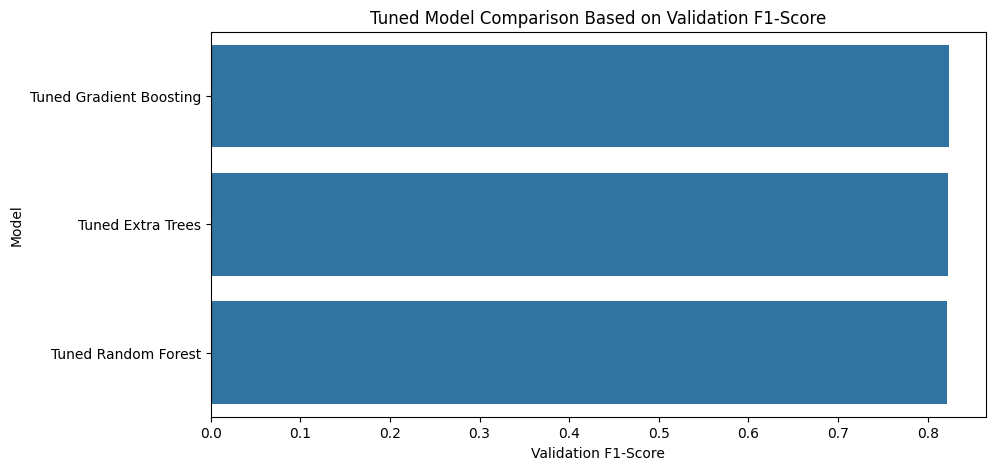

In [108]:
plt.figure(figsize=(10, 5)) # Create a bar plot comparing tuned validation F1-scores.
sns.barplot(data=tuned_results_df, x="Validation F1", y="Model") # Plot validation F1-score for each tuned model.
plt.title("Tuned Model Comparison Based on Validation F1-Score")
plt.xlabel("Validation F1-Score")
plt.ylabel("Model")
plt.show()

In [109]:
best_tuned_model_name = tuned_results_df.iloc[0]["Model"] # Select the best tuned model name based on validation F1-score.
print("Best tuned model:", best_tuned_model_name) # Print the best tuned model name.
best_tuned_model = tuned_models[best_tuned_model_name] # Get the best tuned model object from the tuned model dictionary.
best_tuned_val_preds = best_tuned_model.predict(X_tune_val) # Predict validation labels using the best tuned model.
print(classification_report(y_tune_val, best_tuned_val_preds, target_names=["Denied", "Certified"])) # Print the classification report for the best tuned model.

Best tuned model: Tuned Gradient Boosting
              precision    recall  f1-score   support

      Denied       0.70      0.37      0.48      1269
   Certified       0.75      0.92      0.82      2553

    accuracy                           0.74      3822
   macro avg       0.72      0.64      0.65      3822
weighted avg       0.73      0.74      0.71      3822



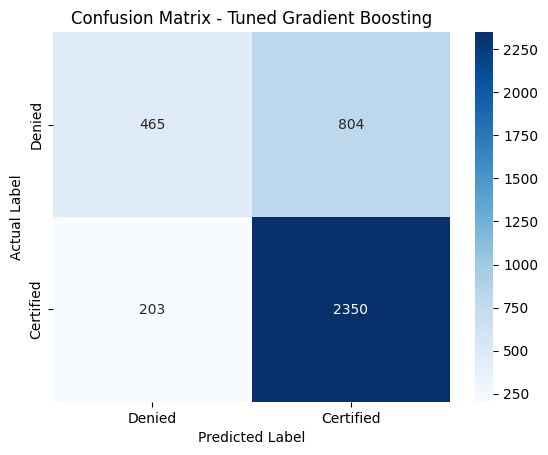

In [110]:
cm_tuned = confusion_matrix(y_tune_val, best_tuned_val_preds) # Create a confusion matrix for the best tuned model.
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Blues", xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"]) # Create a heatmap for the tuned model confusion matrix.
plt.title(f"Confusion Matrix - {best_tuned_model_name}") # Add a title to the confusion matrix.
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [112]:
tuned_results_df["Data Type"] = "Tuned Original Data" # Add a data type column to identify these as tuned model results.
tuned_results_df.T # Display the final tuned model results.

,2,1,0
Model,Tuned Gradient Boosting,Tuned Extra Trees,Tuned Random Forest
Train Accuracy,0.748542,0.761045,0.764297
Validation Accuracy,0.736525,0.745683,0.74516
Train Precision,0.754698,0.783938,0.785075
Validation Precision,0.745086,0.77137,0.770284
Train Recall,0.923781,0.886594,0.891043
Validation Recall,0.920486,0.880141,0.881316
Train F1,0.830723,0.832112,0.834709
Validation F1,0.82355,0.822173,0.822068
Train ROC-AUC,0.792702,0.812667,0.820838


### Conclusion

Three models were selected for hyperparameter tuning:

1. Random Forest
2. Extra Trees
3. Gradient Boosting

These models were chosen because they are tree-based ensemble models and generally perform well on structured tabular data. They can capture non-linear relationships between features and the target variable.

RandomizedSearchCV was used instead of GridSearchCV because it is faster and searches a wide range of hyperparameter combinations efficiently.

F1-score was used as the metric of interest because the target variable is moderately imbalanced and F1-score balances precision and recall.

### Performance Comments

After tuning, validation F1-Score should be considered for the three models.

The optimal tuned model can be chosen depending on:

- Higher validation F1-Score
- High validation recall
- High validation precision
- Narrow gap between training and validation accuracy
- High ROC-AUC Score

A model that exhibits good training results but bad validation results is overfitted.

###Model Performance Comparison and Final Model Selection.

In [113]:
original_results_df["Data Type"] = "Original Data" # Add a data type column to the original model results.
oversampled_results_df["Data Type"] = "Oversampled Data" # Add a data type column to the oversampled model results.
undersampled_results_df["Data Type"] = "Undersampled Data" # Add a data type column to the undersampled model results.
tuned_results_df["Data Type"] = "Tuned Original Data" # Add a data type column to the tuned model results.

In [115]:
all_model_results = pd.concat( # Combine original, oversampled, undersampled, and tuned model results into one dataframe.
    [
        original_results_df,
        oversampled_results_df,
        undersampled_results_df,
        tuned_results_df
    ],
    ignore_index=True
)

all_model_results = all_model_results.sort_values(by="Validation F1", ascending=False) # Sort all models by validation F1-score in descending order.
all_model_results.T  # Display the combined model comparison table.

,18,19,20,0,1,2,6,3,7,4,...,12,9,10,13,5,11,14,15,16,17
Model,Tuned Gradient Boosting,Tuned Extra Trees,Tuned Random Forest,Gradient Boosting,AdaBoost,Random Forest,Extra Trees,Extra Trees,Random Forest,Bagging Classifier,...,Gradient Boosting,Bagging Classifier,AdaBoost,AdaBoost,Decision Tree,Decision Tree,Random Forest,Extra Trees,Bagging Classifier,Decision Tree
Train Accuracy,0.748542,0.761045,0.764297,0.75712,0.738899,1.0,1.0,1.0,0.999958,0.984862,...,0.721087,0.988416,0.693948,0.695256,1.0,1.0,1.0,1.0,0.978389,1.0
Validation Accuracy,0.736525,0.745683,0.74516,0.743328,0.729723,0.722135,0.712977,0.70539,0.709053,0.704605,...,0.709314,0.692308,0.694662,0.689691,0.657509,0.653061,0.677656,0.673469,0.641287,0.616431
Train Precision,0.754698,0.783938,0.785075,0.784252,0.762594,1.0,1.0,1.0,1.0,0.992221,...,0.714637,0.99701,0.680437,0.686022,1.0,1.0,1.0,1.0,0.99116,1.0
Validation Precision,0.745086,0.77137,0.770284,0.773486,0.755892,0.768455,0.761871,0.757488,0.776796,0.771548,...,0.817342,0.786041,0.798193,0.799912,0.74373,0.738438,0.807066,0.799175,0.801223,0.76577
Train Recall,0.923781,0.886594,0.891043,0.877865,0.884412,1.0,1.0,1.0,0.999916,0.985058,...,0.736113,0.97977,0.731386,0.720074,1.0,1.0,1.0,1.0,0.965389,1.0
Validation Recall,0.920486,0.880141,0.881316,0.87074,0.879358,0.835879,0.829612,0.82217,0.792009,0.792401,...,0.72738,0.741089,0.726596,0.714062,0.743439,0.744222,0.679984,0.682726,0.615746,0.613396
Train F1,0.830723,0.832112,0.834709,0.828422,0.818998,1.0,1.0,1.0,0.999958,0.988627,...,0.725216,0.988315,0.704992,0.702636,1.0,1.0,1.0,1.0,0.978105,1.0
Validation F1,0.82355,0.822173,0.822068,0.819237,0.812964,0.80075,0.7943,0.788505,0.784329,0.781836,...,0.769741,0.762903,0.760714,0.754553,0.743585,0.741319,0.738095,0.736375,0.696346,0.681166
Train ROC-AUC,0.792702,0.812667,0.820838,0.796494,0.773265,1.0,1.0,1.0,1.0,0.998554,...,0.79718,0.999595,0.770363,0.772234,1.0,1.0,1.0,1.0,0.998301,1.0


In [116]:
comparison_table = all_model_results[  # Select important columns for a cleaner comparison table.
    [
        "Model",
        "Data Type",
        "Validation Accuracy",
        "Validation Precision",
        "Validation Recall",
        "Validation F1",
        "Validation ROC-AUC"
    ]
]
comparison_table  # Display the cleaner comparison table.

,Model,Data Type,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
18,Tuned Gradient Boosting,Tuned Original Data,0.736525,0.745086,0.920486,0.823550,0.774292
19,Tuned Extra Trees,Tuned Original Data,0.745683,0.771370,0.880141,0.822173,0.781249
20,Tuned Random Forest,Tuned Original Data,0.745160,0.770284,0.881316,0.822068,0.780488
0,Gradient Boosting,Original Data,0.743328,0.773486,0.870740,0.819237,0.779194
1,AdaBoost,Original Data,0.729723,0.755892,0.879358,0.812964,0.762920
2,Random Forest,Original Data,0.722135,0.768455,0.835879,0.800750,0.752953
6,Extra Trees,Oversampled Data,0.712977,0.761871,0.829612,0.794300,0.744761
3,Extra Trees,Original Data,0.705390,0.757488,0.822170,0.788505,0.742291
7,Random Forest,Oversampled Data,0.709053,0.776796,0.792009,0.784329,0.749539
4,Bagging Classifier,Original Data,0.704605,0.771548,0.792401,0.781836,0.725527


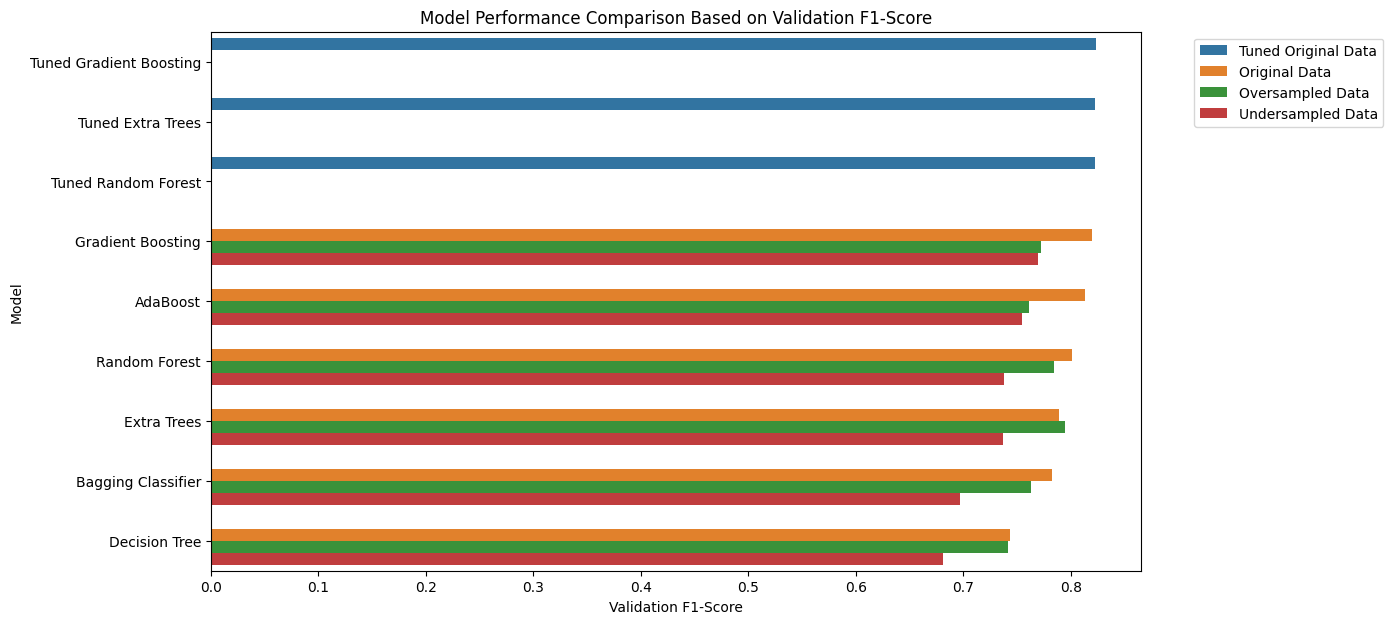

In [117]:
plt.figure(figsize=(12, 7)) # Create a larger figure for model comparison.
sns.barplot(data=comparison_table, x="Validation F1", y="Model", hue="Data Type") # Plot validation F1-score by model and data type.
plt.title("Model Performance Comparison Based on Validation F1-Score")
plt.xlabel("Validation F1-Score")
plt.ylabel("Model")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left") # Move legend outside the plot for readability.
plt.show()

In [118]:
best_model_row = comparison_table.iloc[0]  # Select the best model row based on highest validation F1-score.
print(best_model_row)  # Print the selected best model row.

Model                   Tuned Gradient Boosting
Data Type                   Tuned Original Data
Validation Accuracy                    0.736525
Validation Precision                   0.745086
Validation Recall                      0.920486
Validation F1                           0.82355
Validation ROC-AUC                     0.774292
Name: 18, dtype: object


In [120]:
final_model_name = best_model_row["Model"] # Save the best model name from the comparison table.
final_model_data_type = best_model_row["Data Type"] # Save the best model data type from the comparison table.
print("Final selected model:", final_model_name) # Print the final model name.
print("Final selected model data type:", final_model_data_type) # Print the final model data type.

Final selected model: Tuned Gradient Boosting
Final selected model data type: Tuned Original Data


In [131]:
comparison_table.head(1).T

,18
Model,Tuned Gradient Boosting
Data Type,Tuned Original Data
Validation Accuracy,0.736525
Validation Precision,0.745086
Validation Recall,0.920486
Validation F1,0.82355
Validation ROC-AUC,0.774292


In [122]:
def get_final_model(model_name, data_type): # Define a helper function to retrieve the final model object.

    if data_type == "Original Data": # Check if the best model came from original data.

        return models_original[model_name] # Return the model from original models dictionary.

    elif data_type == "Oversampled Data": # Check if the best model came from oversampled data.

        return models_oversampled[model_name] # Return the model from oversampled models dictionary.

    elif data_type == "Undersampled Data": # Check if the best model came from undersampled data.

        return models_undersampled[model_name] # Return the model from undersampled models dictionary.

    elif data_type == "Tuned Original Data":   # Check if the best model came from tuned original data.

        return tuned_models[model_name]  # Return the model from tuned models dictionary.

    else:   # Raise an error if the data type is not recognized.

        raise ValueError("Unknown data type for final model.") # Stop execution with a clear error message.

In [123]:
final_model = get_final_model(final_model_name, final_model_data_type) # Get the final selected model object.
final_model # Display the final selected model object.

GradientBoostingClassifier(learning_rate=0.01, max_depth=5, min_samples_leaf=4,
                           min_samples_split=5, n_estimators=150,
                           random_state=42, subsample=0.8)

In [124]:
test_preds = final_model.predict(X_test_processed) # Predict labels for the test set using the final selected model.
test_probs = final_model.predict_proba(X_test_processed)[:, 1] # Predict probabilities for the positive class on the test set.

In [125]:
test_accuracy = accuracy_score(y_test, test_preds) # Calculate test accuracy.
test_precision = precision_score(y_test, test_preds) # Calculate test precision.
test_recall = recall_score(y_test, test_preds) # Calculate test recall.
test_f1 = f1_score(y_test, test_preds) # Calculate test F1-score.
test_roc_auc = roc_auc_score(y_test, test_probs) # Calculate test ROC-AUC score.
test_precision = precision_score(y_test, test_preds) # Calculate test precision.
test_recall = recall_score(y_test, test_preds) # Calculate test recall.
test_f1 = f1_score(y_test, test_preds) # Calculate test F1-score.
test_roc_auc = roc_auc_score(y_test, test_probs) # Calculate test ROC-AUC score.

In [126]:
final_test_results = pd.DataFrame(  # Create a dataframe to store final test performance.
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "ROC-AUC"
        ],
        "Test Score": [
            test_accuracy,
            test_precision,
            test_recall,
            test_f1,
            test_roc_auc
        ]
    }
)
final_test_results # Display final test performance.

,Metric,Test Score
0,Accuracy,0.737049
1,Precision,0.747046
2,Recall,0.916536
3,F1-score,0.823157
4,ROC-AUC,0.764282


In [127]:
print(classification_report(y_test, test_preds, target_names=["Denied", "Certified"])) # Print the classification report for the final model on the test set.

              precision    recall  f1-score   support

      Denied       0.69      0.38      0.49      1270
   Certified       0.75      0.92      0.82      2552

    accuracy                           0.74      3822
   macro avg       0.72      0.65      0.66      3822
weighted avg       0.73      0.74      0.71      3822



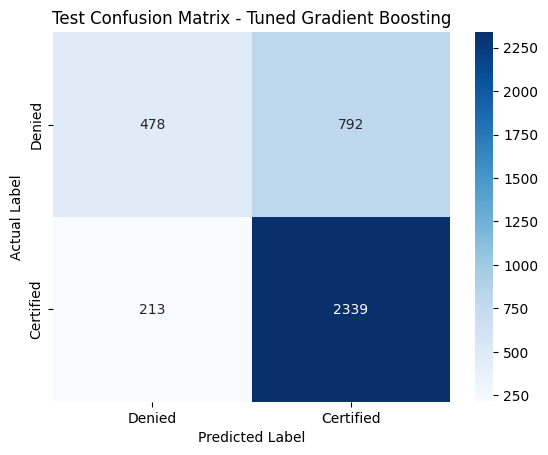

In [128]:
final_cm = confusion_matrix(y_test, test_preds) # Create confusion matrix for final model test predictions.
sns.heatmap(final_cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"]) # Create a heatmap for the final model confusion matrix.
plt.title(f"Test Confusion Matrix - {final_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show() # Display the confusion matrix.

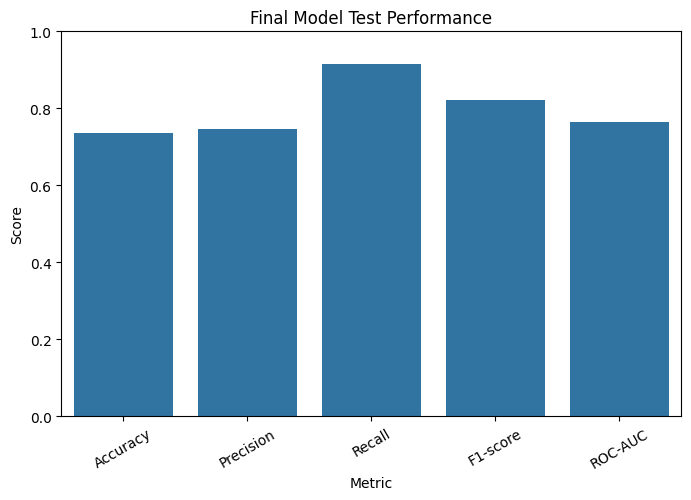

In [129]:
plt.figure(figsize=(8, 5)) # Create a bar chart for final test metrics.
sns.barplot(data=final_test_results, x="Metric", y="Test Score") # Plot each test metric score.
plt.title("Final Model Test Performance")
plt.ylabel("Score")
plt.xticks(rotation=30) # Rotate x-axis labels for readability.
plt.ylim(0, 1) # Set y-axis limit from 0 to 1.
plt.show()

###Conclusion

All models built on original, oversampled, undersampled, and tuned data were compared using validation performance.

The main metric used for selecting the final model was F1-score because the target variable is moderately imbalanced and F1-score balances precision and recall.

The final model was selected based on:

1. Highest validation F1-score
2. Good validation recall
3. Good validation precision
4. Good ROC-AUC score
5. Reasonable difference between training and validation performance

After selecting the final model, its performance was evaluated on the test set. The test set was not used during training, preprocessing fitting, resampling, or hyperparameter tuning. Therefore, test performance gives a better estimate of how the model may perform on unseen visa applications.

### Final Model Performance Comment

The final model shows how well the selected machine learning approach generalizes to unseen data.

If the test F1-score is close to the validation F1-score, the model generalizes well.

If the test score is much lower than validation score, the model may be overfitting and should be reviewed further.

The confusion matrix should also be checked to understand how many Certified and Denied applications were correctly and incorrectly predicted.